## Plan de l'Atelier d'Analyse de Données avec Pandas et Matplotlib
### Base de Pandas

In [1]:
import sys
print(sys.version)  # 3.12.6

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print(pd.__version__) #intallation done

# dataFrame display options
pd.set_option('display.min_rows', 6)
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 20)
pd.set_option('display.width', 240)

3.12.3 (main, Mar  3 2026, 12:15:18) [GCC 13.3.0]


3.0.2


In [2]:
# random seed for reproducibility
np.random.seed(42)  

df_random = pd.DataFrame(
    np.random.randn(200, 20),
    columns=[f"col_{i}" for i in range(20)]
)

print(df_random)

        col_0     col_1     col_2     col_3     col_4     col_5  ...    col_14    col_15    col_16    col_17    col_18    col_19
0    0.496714 -0.138264  0.647689  1.523030 -0.234153 -0.234137  ... -1.724918 -0.562288 -1.012831  0.314247 -0.908024 -1.412304
1    1.465649 -0.225776  0.067528 -1.424748 -0.544383  0.110923  ...  0.822545 -1.220844  0.208864 -1.959670 -1.328186  0.196861
2    0.738467  0.171368 -0.115648 -0.301104 -1.478522 -0.719844  ...  1.031000  0.931280 -0.839218 -0.309212  0.331263  0.975545
..        ...       ...       ...       ...       ...       ...  ...       ...       ...       ...       ...       ...       ...
197  0.379153  1.230222 -0.596974 -2.390304 -0.412221  0.913474  ... -0.580648 -0.611385 -0.092944 -0.239502  1.116834  0.186416
198 -0.731632  1.890441  0.049308  0.768840 -0.608227  0.363116  ...  0.355669  0.191577  0.506241  1.447306  0.568103 -1.049655
199  1.362563  1.640615  3.152057 -1.123494  0.242882 -2.082099  ... -2.065083  0.028458 -2.07781

#### Concepts de base — DataFrame / Series / Index (rapide)

- DataFrame : tableau 2D (lignes × colonnes), comme une feuille Excel
- Series : une seule colonne d'un DataFrame (1D), avec un Index associé. df['col_0'] qui retourne une series
- Index : les "étiquettes" des lignes (par défaut 0,1,2,... mais peut être de n'importe quel type). Il sert à aligner/joindre les données

In [3]:
type(df_random)          # DataFrame
type(df_random['col_0'])  # Series
df_random.index          # RangeIndex(start=0, stop=200, step=1)

RangeIndex(start=0, stop=200, step=1)

### Chargement et exploitation des données 

In [4]:
chemin_fichier = "CC-AIBD-DataAnalyse-donnees.xlsx"

orders      = pd.read_excel(chemin_fichier, sheet_name="Sales Order_data")
territories = pd.read_excel(chemin_fichier, sheet_name="Sales Territory_data")
sales       = pd.read_excel(chemin_fichier, sheet_name="Sales_data")
resellers   = pd.read_excel(chemin_fichier, sheet_name="Reseller_data")
dates       = pd.read_excel(chemin_fichier, sheet_name="Date_data")
products    = pd.read_excel(chemin_fichier, sheet_name="Product_data")
customers   = pd.read_excel(chemin_fichier, sheet_name="Customer_data")

# petit contrôle rapide
for nom, df in [("orders", orders), ("territories", territories), ("sales", sales),
                 ("resellers", resellers), ("dates", dates), ("products", products),
                 ("customers", customers)]:
    print(nom, df.shape)

orders (121253, 4)
territories (11, 4)
sales (121253, 15)
resellers (702, 8)
dates (1461, 7)
products (397, 9)
customers (18485, 7)


In [5]:
#diplay first 5 rows of each dataframe
for nom, df in [("orders", orders), ("territories", territories), ("sales", sales),
                 ("resellers", resellers), ("dates", dates), ("products", products),
                 ("customers", customers)]:
    print(f"===== {nom} =====")
    display(df.head())     
    print(df.dtypes)
    print()

===== orders =====


,Channel,SalesOrderLineKey,Sales Order,Sales Order Line
0,Reseller,43659001,SO43659,SO43659 - 1
1,Reseller,43659002,SO43659,SO43659 - 2
2,Reseller,43659003,SO43659,SO43659 - 3
3,Reseller,43659004,SO43659,SO43659 - 4
4,Reseller,43659005,SO43659,SO43659 - 5


Channel                str
SalesOrderLineKey    int64
Sales Order            str
Sales Order Line       str
dtype: object

===== territories =====


,SalesTerritoryKey,Region,Country,Group
0,1,Northwest,United States,North America
1,2,Northeast,United States,North America
2,3,Central,United States,North America
3,4,Southwest,United States,North America
4,5,Southeast,United States,North America


SalesTerritoryKey    int64
Region                 str
Country                str
Group                  str
dtype: object

===== sales =====


,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,...,Unit Price,Extended Amount,Unit Price Discount Pct,Product Standard Cost,Total Product Cost,Sales Amount
0,43659001,676,-1,349,20170702,20170712,...,2024.994,2024.994,0,1898.0944,1898.0944,2024.994
1,43659002,676,-1,350,20170702,20170712,...,2024.994,6074.982,0,1898.0944,5694.2832,6074.982
2,43659003,676,-1,351,20170702,20170712,...,2024.994,2024.994,0,1898.0944,1898.0944,2024.994
3,43659004,676,-1,344,20170702,20170712,...,2039.994,2039.994,0,1912.1544,1912.1544,2039.994
4,43659005,676,-1,345,20170702,20170712,...,2039.994,2039.994,0,1912.1544,1912.1544,2039.994


... (5 outputs left out)

,ProductKey,SKU,Product,Standard Cost,Color,List Price,Model,Subcategory,Category
0,210,FR-R92B-58,HL Road Frame - ...,868.6342,Black,1431.5000,HL Road Frame,Road Frames,Components
1,211,FR-R92R-58,HL Road Frame - ...,868.6342,Red,1431.5000,HL Road Frame,Road Frames,Components
2,212,HL-U509-R,Sport-100 Helmet...,12.0278,Red,33.6442,Sport-100,Helmets,Accessories
3,213,HL-U509-R,Sport-100 Helmet...,13.8782,Red,33.6442,Sport-100,Helmets,Accessories
4,214,HL-U509-R,Sport-100 Helmet...,13.0863,Red,34.9900,Sport-100,Helmets,Accessories


ProductKey         int64
SKU                  str
Product              str
Standard Cost    float64
Color                str
List Price       float64
Model                str
Subcategory          str
Category             str
dtype: object

===== customers =====


,CustomerKey,Customer ID,Customer,City,State-Province,Country-Region,Postal Code
0,-1,[Not Applicable],[Not Applicable],[Not Applicable],[Not Applicable],[Not Applicable],[Not Applicable]
1,11000,AW00011000,Jon Yang,Rockhampton,Queensland,Australia,4700
2,11001,AW00011001,Eugene Huang,Seaford,Victoria,Australia,3198
3,11002,AW00011002,Ruben Torres,Hobart,Tasmania,Australia,7001
4,11003,AW00011003,Christy Zhu,North Ryde,New South Wales,Australia,2113


CustomerKey       int64
Customer ID         str
Customer            str
City                str
State-Province      str
Country-Region      str
Postal Code         str
dtype: object



In [6]:
#dataframe info 
for nom, df in [("orders", orders), ("territories", territories), ("sales", sales),
                 ("resellers", resellers), ("dates", dates), ("products", products),
                 ("customers", customers)]:
    print(f"---- {nom} — info() ----")
    df.info()
    print(f"\n---- {nom} — describe() ----")
    display(df.describe(include='all'))
    print("\n")

---- orders — info() ----
<class 'pandas.DataFrame'>
RangeIndex: 121253 entries, 0 to 121252
Data columns (total 4 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   Channel            121253 non-null  str  
 1   SalesOrderLineKey  121253 non-null  int64
 2   Sales Order        121253 non-null  str  
 3   Sales Order Line   121253 non-null  str  
dtypes: int64(1), str(3)
memory usage: 3.7 MB

---- orders — describe() ----


,Channel,SalesOrderLineKey,Sales Order,Sales Order Line
count,121253,1.212530e+05,121253,121253
unique,2,NaN,31455,121253
top,Reseller,NaN,SO51721,SO43659 - 1
freq,60855,NaN,72,1
mean,NaN,5.782642e+07,NaN,NaN
std,NaN,9.009990e+06,NaN,NaN
min,NaN,4.365900e+07,NaN,NaN
25%,NaN,4.987905e+07,NaN,NaN
50%,NaN,5.702800e+07,NaN,NaN
75%,NaN,6.549000e+07,NaN,NaN




---- territories — info() ----
<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   SalesTerritoryKey  11 non-null     int64
 1   Region             11 non-null     str  
 2   Country            11 non-null     str  
 3   Group              11 non-null     str  
dtypes: int64(1), str(3)
memory usage: 484.0 bytes

---- territories — describe() ----


,SalesTerritoryKey,Region,Country,Group
count,11.000000,11,11,11
unique,NaN,11,7,4
top,NaN,Northwest,United States,North America
freq,NaN,1,5,6
mean,6.000000,NaN,NaN,NaN
std,3.316625,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN
25%,3.500000,NaN,NaN,NaN
50%,6.000000,NaN,NaN,NaN
75%,8.500000,NaN,NaN,NaN




---- sales — info() ----
<class 'pandas.DataFrame'>
RangeIndex: 121253 entries, 0 to 121252
Data columns (total 15 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   SalesOrderLineKey        121253 non-null  int64  
 1   ResellerKey              121253 non-null  int64  
 2   CustomerKey              121253 non-null  int64  
 3   ProductKey               121253 non-null  int64  
 4   OrderDateKey             121253 non-null  int64  
 5   DueDateKey               121253 non-null  int64  
 6   ShipDateKey              119140 non-null  float64
 7   SalesTerritoryKey        121253 non-null  int64  
 8   Order Quantity           121253 non-null  int64  
 9   Unit Price               121253 non-null  float64
 10  Extended Amount          121253 non-null  float64
 11  Unit Price Discount Pct  121253 non-null  int64  
 12  Product Standard Cost    121253 non-null  float64
 13  Total Product Cost       121253 non-null  f

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,...,Unit Price,Extended Amount,Unit Price Discount Pct,Product Standard Cost,Total Product Cost,Sales Amount
count,1.212530e+05,121253.000000,121253.000000,121253.000000,1.212530e+05,1.212530e+05,...,121253.000000,121253.000000,121253.0,121253.000000,121253.000000,121253.000000
mean,5.782642e+07,170.043430,9384.833868,424.884094,2.019158e+07,2.019183e+07,...,465.180515,909.971564,0.0,362.643598,802.107230,905.621091
std,9.009990e+06,224.536697,10171.582167,116.978898,7.981850e+03,8.021172e+03,...,752.041893,1705.565586,0.0,541.688873,1660.416044,1693.746343
min,4.365900e+07,-1.000000,-1.000000,212.000000,2.017070e+07,2.017071e+07,...,1.328200,1.374000,0.0,0.856500,0.856500,1.374000
25%,4.987905e+07,-1.000000,-1.000000,339.000000,2.019041e+07,2.019042e+07,...,21.490000,24.990000,0.0,9.159300,10.842300,24.990000
50%,5.702800e+07,3.000000,-1.000000,470.000000,2.019101e+07,2.019102e+07,...,49.990000,134.982000,0.0,38.492300,98.983600,134.982000
75%,6.549000e+07,327.000000,18116.000000,528.000000,2.020022e+07,2.020030e+07,...,602.346000,1120.490000,0.0,486.706600,999.259500,1120.490000
max,7.512300e+07,701.000000,29483.000000,606.000000,2.020062e+07,2.020062e+07,...,3578.270000,30992.910000,0.0,2171.294200,38530.385400,27893.619000


... (4 outputs left out)



---- products — info() ----
<class 'pandas.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ProductKey     397 non-null    int64  
 1   SKU            397 non-null    str    
 2   Product        397 non-null    str    
 3   Standard Cost  397 non-null    float64
 4   Color          341 non-null    str    
 5   List Price     397 non-null    float64
 6   Model          397 non-null    str    
 7   Subcategory    397 non-null    str    
 8   Category       397 non-null    str    
dtypes: float64(2), int64(1), str(6)
memory usage: 28.0 KB

---- products — describe() ----


,ProductKey,SKU,Product,Standard Cost,Color,List Price,Model,Subcategory,Category
count,397.000000,397,397,397.000000,341,397.000000,397,397,397
unique,NaN,295,295,NaN,9,NaN,119,37,4
top,NaN,HL-U509-R,Sport-100 Helmet...,NaN,Black,NaN,LL Road Frame,Road Frames,Components
freq,NaN,3,3,NaN,129,NaN,30,70,189
mean,408.000000,NaN,NaN,436.454083,NaN,751.106791,NaN,NaN,NaN
std,114.748275,NaN,NaN,497.076884,NaN,837.991094,NaN,NaN,NaN
min,210.000000,NaN,NaN,0.856500,NaN,2.290000,NaN,NaN,NaN
25%,309.000000,NaN,NaN,37.120900,NaN,69.990000,NaN,NaN,NaN
50%,408.000000,NaN,NaN,204.625100,NaN,364.090000,NaN,NaN,NaN
75%,507.000000,NaN,NaN,660.914200,NaN,1214.850000,NaN,NaN,NaN




---- customers — info() ----
<class 'pandas.DataFrame'>
RangeIndex: 18485 entries, 0 to 18484
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerKey     18485 non-null  int64
 1   Customer ID     18485 non-null  str  
 2   Customer        18485 non-null  str  
 3   City            18485 non-null  str  
 4   State-Province  18485 non-null  str  
 5   Country-Region  18485 non-null  str  
 6   Postal Code     18485 non-null  str  
dtypes: int64(1), str(6)
memory usage: 1011.0 KB

---- customers — describe() ----


,CustomerKey,Customer ID,Customer,City,State-Province,Country-Region,Postal Code
count,18485.000000,18485,18485,18485,18485,18485,18485
unique,NaN,18485,18401,270,54,7,324
top,NaN,[Not Applicable],Mohamed Pal,London,California,United States,94519
freq,NaN,1,3,420,4444,7819,212
mean,20240.404923,NaN,NaN,NaN,NaN,NaN,NaN
std,5337.947953,NaN,NaN,NaN,NaN,NaN,NaN
min,-1.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,15620.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,20241.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,24862.000000,NaN,NaN,NaN,NaN,NaN,NaN


OrderDateKey, DueDateKey, ShipDateKey (dans sales) => des entiers qui representent des dates 


**Colonnes dont le type semble incorrect vis-à-vis de leur usage :**

| Table | Colonne(s) | Problème | Correction prévue |
|---|---|---|---|
| `sales` | `OrderDateKey`, `DueDateKey`, `ShipDateKey` | entiers `AAAAMMJJ` (et `float64` pour `ShipDateKey` à cause des valeurs vides) | convertir en `datetime64` |
| `sales` | `Unit Price Discount Pct` | entier, toujours à 0 alors que les montants montrent des remises | recalculer la remise à partir des montants |
| `orders` | `Sales Order Line` | texte `SO43659 - 1` qui contient le numéro de ligne | extraire le numéro en entier |
| `dates` | `Full Date` | texte alors que `Date` est déjà un vrai `datetime` | on utilise `Date` |
| `products` | `Color` | 56 valeurs vides | valeur de repli |
| plusieurs | `Channel`, `Category`, `Group`… | peu de valeurs distinctes en `str` | `category` (gain mémoire, tri) |

### Dispersion du coût standard des produits

In [7]:
cout = products['Standard Cost']
print(f"Médiane      : {cout.median():10.2f}")
print(f"Écart-type   : {cout.std():10.2f}")
print(f"Variance     : {cout.var():10.2f}")

Médiane      :     204.63
Écart-type   :     497.08
Variance     :  247085.43


In [8]:
# même chose par catégorie de produit
disp_cat = products.groupby('Category')['Standard Cost'].agg(
    nb_produits='count', mediane='median', ecart_type='std', variance='var'
)
display(disp_cat.round(2))

,nb_produits,mediane,ecart_type,variance
Category,,,,
Accessories,35,11.22,13.13,172.34
Bikes,125,713.08,552.41,305153.73
Clothing,48,26.18,12.42,154.37
Components,189,187.16,280.64,78756.88


> Le coût standard est très dispersé (écart-type supérieur à la médiane) : le catalogue mélange des accessoires à quelques dollars et des vélos à plus de 2 000 $. La dispersion est surtout portée par la catégorie `Bikes`.

## Jour 1 — 3. Nettoyage des données

### 3.1 Valeurs vides

In [9]:
tables = {"orders": orders, "territories": territories, "sales": sales,
          "resellers": resellers, "dates": dates, "products": products, "customers": customers}

for nom, df in tables.items():
    vides = df.columns[df.isna().any()].tolist()
    print(f"{nom:12s} -> colonnes avec valeurs vides : {vides if vides else 'aucune'}")
    for col in vides:
        print(f"{'':15s}{col} : {df[col].isna().sum()} valeurs vides")

orders       -> colonnes avec valeurs vides : aucune
territories  -> colonnes avec valeurs vides : aucune
sales        -> colonnes avec valeurs vides : ['ShipDateKey']
               ShipDateKey : 2113 valeurs vides
resellers    -> colonnes avec valeurs vides : aucune
dates        -> colonnes avec valeurs vides : aucune
products     -> colonnes avec valeurs vides : ['Color']
               Color : 56 valeurs vides
customers    -> colonnes avec valeurs vides : aucune


In [10]:
# ShipDateKey : à quelles commandes correspondent les dates d'expédition vides ?
vides_ship = sales[sales['ShipDateKey'].isna()]
print("Dates de commande concernées :", vides_ship['OrderDateKey'].min(), "->", vides_ship['OrderDateKey'].max())
print("Dernière date de commande du jeu de données :", sales['OrderDateKey'].max())

Dates de commande concernées : 20200609 -> 20200615
Dernière date de commande du jeu de données : 20200615


- `Color` : 56 produits (composants et accessoires) n'ont pas de couleur. On les remplace par une valeur de repli explicite, `"Sans couleur"`.
- `ShipDateKey` : les valeurs vides correspondent uniquement aux commandes du 9 au 15 juin 2020, qui ne sont **pas encore expédiées**. Ce n'est pas une erreur de saisie : inventer une date fausserait les délais de livraison. On garde donc une valeur vide (`NaT` après conversion) et on ajoute une colonne booléenne `Is Shipped`.

In [11]:
products['Color'] = products['Color'].fillna('Sans couleur')
print("Valeurs vides restantes dans products :", int(products.isna().sum().sum()))

Valeurs vides restantes dans products : 0


### 3.2 Vérification du total des ventes (et des remises)

In [12]:
# Contrôles de cohérence des montants
ecart_ext  = (sales['Unit Price'] * sales['Order Quantity'] - sales['Extended Amount']).abs()
ecart_cout = (sales['Product Standard Cost'] * sales['Order Quantity'] - sales['Total Product Cost']).abs()
print("Extended Amount != prix x quantité :", int((ecart_ext > 0.01).sum()), "lignes")
print("Total Product Cost != coût x quantité :", int((ecart_cout > 0.01).sum()), "lignes")

# Sales Amount devrait valoir Extended Amount x (1 - remise)
sales['Expected Amount'] = sales['Extended Amount'] * (1 - sales['Unit Price Discount Pct'])
ecart_vente = (sales['Expected Amount'] - sales['Sales Amount']).abs()
print("Sales Amount incohérent avec la remise stockée :", int((ecart_vente > 0.01).sum()), "lignes")
print("Valeurs de Unit Price Discount Pct :", sales['Unit Price Discount Pct'].unique())

Extended Amount != prix x quantité : 0 lignes
Total Product Cost != coût x quantité : 0 lignes
Sales Amount incohérent avec la remise stockée : 3282 lignes
Valeurs de Unit Price Discount Pct : [0]


La colonne `Unit Price Discount Pct` est **toujours égale à 0** (elle a été stockée comme entier, donc les pourcentages ont été tronqués à 0), alors que 3 282 lignes ont un `Sales Amount` inférieur à `Extended Amount`. La remise réelle peut se retrouver à partir des montants : `1 - Sales Amount / Extended Amount`.

In [13]:
remise_implicite = 1 - sales['Sales Amount'] / sales['Extended Amount']
sales['Discount Pct'] = remise_implicite.round(2)

print("Remises retrouvées :", [float(x) for x in sorted(sales.loc[sales['Discount Pct'] > 0, 'Discount Pct'].unique())])
print("Lignes remisées :", int((sales['Discount Pct'] > 0).sum()))

# Vérification finale avec la remise reconstruite
sales['Expected Amount'] = sales['Extended Amount'] * (1 - sales['Discount Pct'])
print("Écart maximal restant :", round((sales['Expected Amount'] - sales['Sales Amount']).abs().max(), 4))
sales = sales.drop(columns='Expected Amount')

Remises retrouvées : [0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.35, 0.4]
Lignes remisées : 3282
Écart maximal restant : 0.0001


### 3.3 Colonnes `Price ratio`, `Line number`, types et `Margin`

In [14]:
# Price ratio : multiplicateur entre le prix affiché et le coût du produit
sales['Price ratio']        = sales['Unit Price'] / sales['Product Standard Cost']        # prix de vente réel / coût
products['List price ratio'] = products['List Price'] / products['Standard Cost']         # prix catalogue / coût

display(sales['Price ratio'].describe().round(2))
display(products['List price ratio'].describe().round(2))

count    121253.00
mean          1.72
std           0.71
min           0.37
25%           1.08
50%           1.57
75%           2.67
max           2.67
Name: Price ratio, dtype: float64

count    397.00
mean       1.93
std        0.37
min        1.30
25%        1.65
50%        1.80
75%        2.25
max        2.80
Name: List price ratio, dtype: float64

In [15]:
# Line number : numéro de ligne extrait de 'SO43659 - 1'
orders['Line number'] = orders['Sales Order Line'].str.extract(r'-\s*(\d+)\s*$')[0].astype(int)
display(orders.head())
print("Valeurs vides :", int(orders['Line number'].isna().sum()), "| max :", orders['Line number'].max())

,Channel,SalesOrderLineKey,Sales Order,Sales Order Line,Line number
0,Reseller,43659001,SO43659,SO43659 - 1,1
1,Reseller,43659002,SO43659,SO43659 - 2,2
2,Reseller,43659003,SO43659,SO43659 - 3,3
3,Reseller,43659004,SO43659,SO43659 - 4,4
4,Reseller,43659005,SO43659,SO43659 - 5,5


Valeurs vides : 0 | max : 72


In [16]:
# Conversion des colonnes de dates AAAAMMJJ -> datetime
for col in ['OrderDateKey', 'DueDateKey', 'ShipDateKey']:
    nom = col.replace('Key', '')
    sales[nom] = pd.to_datetime(sales[col].astype('Int64').astype('string'), format='%Y%m%d')
sales['Is Shipped'] = sales['ShipDate'].notna()

# Année / trimestre fiscal (juillet -> juin) issus de la table dates
cal = dates.set_index('DateKey')
sales['Fiscal Year']    = sales['OrderDateKey'].map(cal['Fiscal Year'])
sales['Fiscal Quarter'] = sales['OrderDateKey'].map(cal['Fiscal Quarter'])

# Colonnes à peu de valeurs distinctes -> category
orders['Channel']          = orders['Channel'].astype('category')
territories['Group']       = territories['Group'].astype('category')
for col in ['Category', 'Subcategory', 'Color']:
    products[col] = products[col].astype('category')

# Exercice de contrôle : types après conversion
print(sales[['OrderDate', 'DueDate', 'ShipDate', 'Is Shipped']].dtypes)
display(sales[['OrderDateKey', 'OrderDate', 'ShipDate', 'Is Shipped']].tail(3))

OrderDate     datetime64[us]
DueDate       datetime64[us]
ShipDate      datetime64[us]
Is Shipped              bool
dtype: object


,OrderDateKey,OrderDate,ShipDate,Is Shipped
121250,20200615,2020-06-15,NaT,False
121251,20200615,2020-06-15,NaT,False
121252,20200615,2020-06-15,NaT,False


In [17]:
# Margin : marge entre les ventes et le coût total
sales['Margin'] = sales['Sales Amount'] - sales['Total Product Cost']
sales['Margin Pct'] = sales['Margin'] / sales['Sales Amount']

print(f"Marge totale : {sales['Margin'].sum():,.0f} $  ({sales['Margin'].sum() / sales['Sales Amount'].sum():.1%} des ventes)")
print(f"Lignes vendues à perte : {(sales['Margin'] < 0).sum()} ({(sales['Margin'] < 0).mean():.1%})")

Marge totale : 12,551,366 $  (11.4% des ventes)
Lignes vendues à perte : 21829 (18.0%)


## Jour 2 — 4. Analyse exploratoire (EDA)

### Thème graphique commun (police, couleurs, grille)

In [18]:
import os
from cycler import cycler

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

PALETTE = ['#1f4e79', '#2e86ab', '#f18f01', '#c73e1d', '#6b9080',
           '#8d6a9f', '#a4ac86', '#e0a458', '#4f5d75', '#bc4749']

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],   # police personnalisée
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.prop_cycle": cycler(color=PALETTE),                  # thème de couleurs
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

def fmt_usd(v):
    """12_345_678 -> '$12.3M' ; 45_000 -> '$45K'"""
    if v == 0:
        return "$0"
    return f"${v/1e6:.1f}M" if abs(v) >= 1e6 else f"${v/1e3:.0f}K"

In [19]:
# Tables enrichies (ventes + produit + territoire) utilisées dans toute l'EDA
sales_e = (sales
    .merge(products[['ProductKey', 'Product', 'Model', 'Subcategory', 'Category']], on='ProductKey', how='left', validate='many_to_one')
    .merge(territories[['SalesTerritoryKey', 'Region', 'Country', 'Group']], on='SalesTerritoryKey', how='left', validate='many_to_one')
)
assert len(sales_e) == len(sales)
print("Ventes totales :", f"{sales['Sales Amount'].sum():,.0f} $")

Ventes totales : 109,809,274 $


### 4.1 Ventes par territoire (barres)

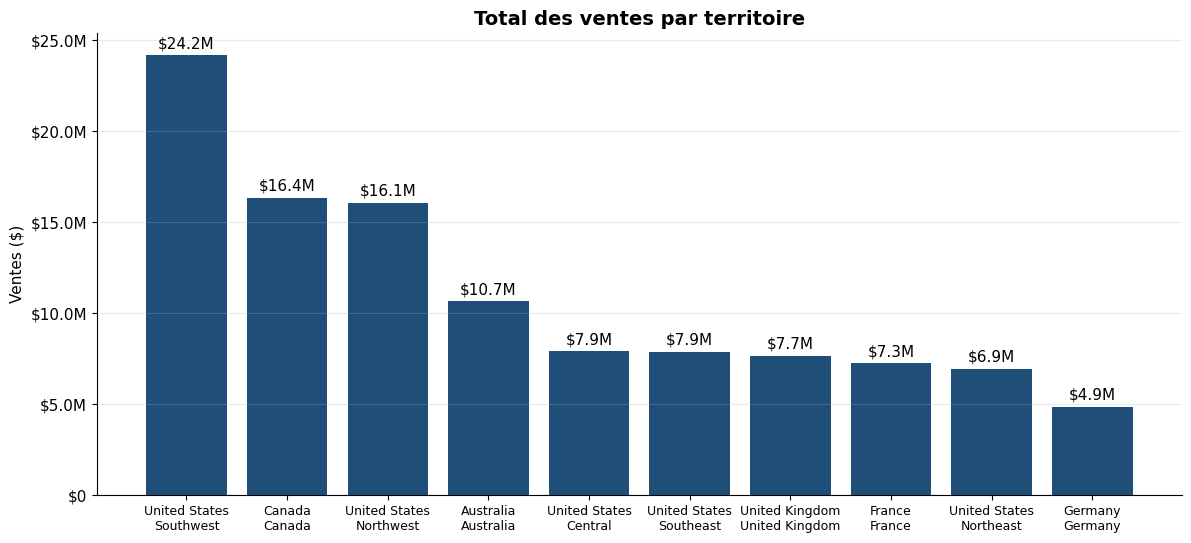

In [20]:
v_terr = (sales_e.groupby(['Country', 'Region'])['Sales Amount'].sum()
          .reset_index().sort_values('Sales Amount', ascending=False))
etiquettes = v_terr['Country'] + "\n" + v_terr['Region']          # Country, puis Region sur la 2e ligne

fig, ax = plt.subplots(figsize=(14, 6))
barres = ax.bar(etiquettes, v_terr['Sales Amount'], color=PALETTE[0])
ax.bar_label(barres, labels=[fmt_usd(v) for v in v_terr['Sales Amount']], padding=3)
ax.tick_params(axis='x', labelrotation=0, labelsize=9)             # intitulés horizontaux
ax.set_title("Total des ventes par territoire")
ax.set_ylabel("Ventes ($)")
ax.yaxis.set_major_formatter(lambda v, _: fmt_usd(v))
ax.grid(axis='x', visible=False)
fig.savefig(f"{FIG_DIR}/ventes_par_territoire.png")
plt.show()

### 4.2 Ventes par modèle de produit

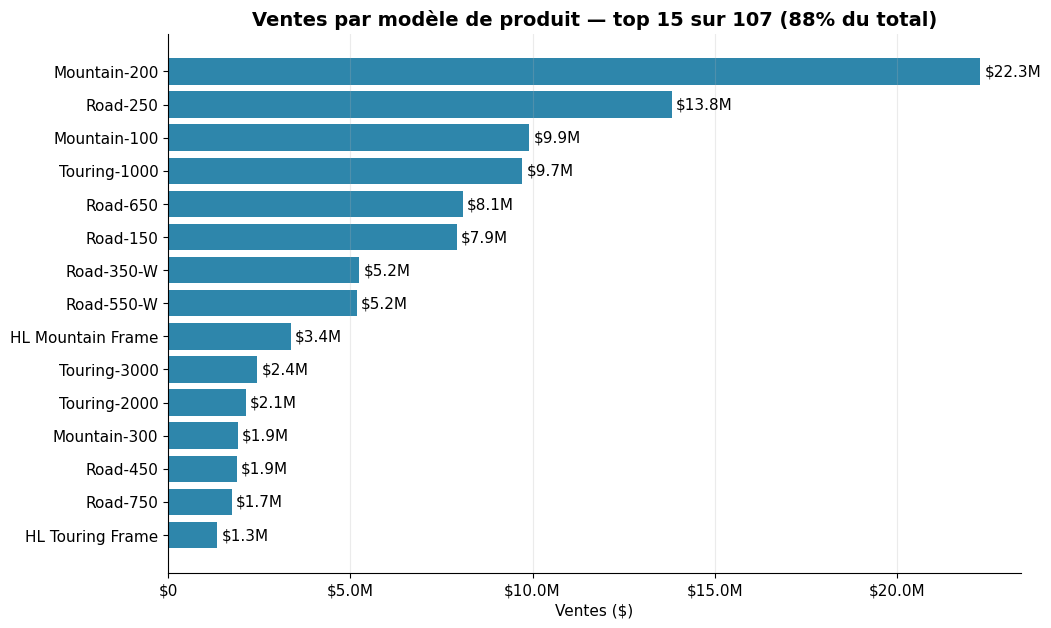

In [21]:
v_mod = sales_e.groupby('Model')['Sales Amount'].sum().sort_values(ascending=False)
top = v_mod.head(15).sort_values()                                  # 15 premiers, tri croissant pour barh
part_top = v_mod.head(15).sum() / v_mod.sum()

fig, ax = plt.subplots(figsize=(11, 7))
barres = ax.barh(top.index, top.values, color=PALETTE[1])
ax.bar_label(barres, labels=[fmt_usd(v) for v in top.values], padding=3)
ax.set_title(f"Ventes par modèle de produit — top 15 sur {len(v_mod)} ({part_top:.0%} du total)")
ax.set_xlabel("Ventes ($)")
ax.xaxis.set_major_formatter(lambda v, _: fmt_usd(v))
ax.grid(axis='y', visible=False)
fig.savefig(f"{FIG_DIR}/ventes_par_modele.png")
plt.show()

> **Lecture** : les ventes sont très concentrées. Les 15 premiers modèles (sur 107 modèles réellement vendus) font 88 % du chiffre d'affaires ; `Mountain-200` représente à lui seul 20 %, devant `Road-250` (12,6 %) et `Mountain-100` (9,0 %). Le catalogue compte 119 modèles : 12 n'ont jamais été vendus sur la période.

### 4.3 Ventes par jour, saisonnalité et moyennes lissées

,Sales,MA7,MA30
OrderDate,,,
2020-06-11,187896.0920,224744.154171,196028.304663
2020-06-12,206796.3412,216145.269971,198949.728670
2020-06-13,68043.5916,144472.965743,194107.857517
2020-06-14,135197.2501,140786.777486,188766.040470
2020-06-15,373021.6019,183010.486743,198141.672573


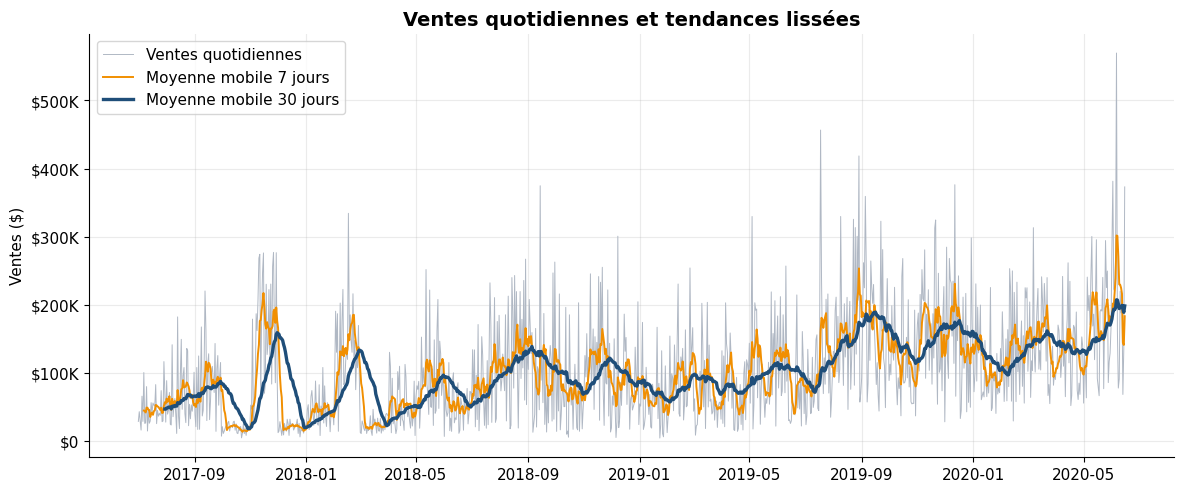

In [22]:
quotidien = (sales.groupby('OrderDate')['Sales Amount'].sum()
             .asfreq('D', fill_value=0).to_frame('Sales'))
quotidien['MA7']  = quotidien['Sales'].rolling(7).mean()
quotidien['MA30'] = quotidien['Sales'].rolling(30).mean()
display(quotidien.tail())

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(quotidien.index, quotidien['Sales'], color='#b0b8c4', lw=0.7, label="Ventes quotidiennes")
ax.plot(quotidien.index, quotidien['MA7'],  color=PALETTE[2], lw=1.4, label="Moyenne mobile 7 jours")
ax.plot(quotidien.index, quotidien['MA30'], color=PALETTE[0], lw=2.4, label="Moyenne mobile 30 jours")
ax.set_title("Ventes quotidiennes et tendances lissées")
ax.set_ylabel("Ventes ($)")
ax.yaxis.set_major_formatter(lambda v, _: fmt_usd(v))
ax.legend(loc='upper left')
fig.savefig(f"{FIG_DIR}/ventes_quotidiennes.png")
plt.show()

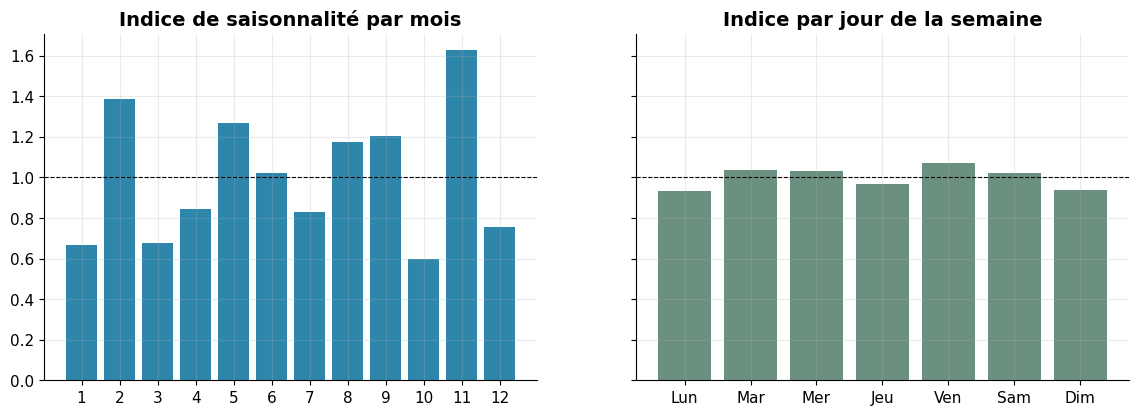

{1: 0.67, 2: 1.39, 3: 0.68, 4: 0.85, 5: 1.27, 6: 1.02, 7: 0.83, 8: 1.18, 9: 1.2, 10: 0.6, 11: 1.63, 12: 0.75}


In [23]:
# Indice de saisonnalité : ventes moyennes d'un jour / moyenne de son année fiscale (1.0 = jour "normal").
# On neutralise ainsi la forte croissance d'une année sur l'autre, qui fausserait une simple moyenne par mois.
fy_jour = dates.set_index('Date')['Fiscal Year'].reindex(quotidien.index)
indice = quotidien['Sales'] / quotidien['Sales'].groupby(fy_jour).transform('mean')
indice_mois  = indice.groupby(quotidien.index.month).mean()
indice_jours = indice.groupby(quotidien.index.dayofweek).mean()
jours = ['Lun', 'Mar', 'Mer', 'Jeu', 'Ven', 'Sam', 'Dim']

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
axes[0].bar(indice_mois.index, indice_mois.values, color=PALETTE[1])
axes[0].set_xticks(range(1, 13))
axes[0].set_title("Indice de saisonnalité par mois")
axes[1].bar(jours, indice_jours.values, color=PALETTE[4])
axes[1].set_title("Indice par jour de la semaine")
for ax in axes:
    ax.axhline(1, color='black', lw=0.8, ls='--')
plt.show()
print(indice_mois.round(2).to_dict())

> **Lecture** : la moyenne mobile à 30 jours montre une croissance nette et continue sur les trois ans. L'indice de saisonnalité (1,0 = jour moyen de l'année fiscale) fait ressortir des pics en novembre (1,63), février (1,39) et mai (1,27), et des creux en octobre (0,60), janvier et mars (≈ 0,67). L'effet du jour de la semaine est faible (de l'ordre de ± 6 %).
> **Prudence** : avec seulement trois ans de données, ces pics ne prouvent pas une saisonnalité commerciale. Ils peuvent aussi venir de grosses commandes de revendeurs regroupées à certaines dates.

### 4.4 Tableaux croisés dynamiques

In [24]:
def trier_pivot(p, nom_total='Total'):
    # Trie les lignes par total décroissant en gardant la ligne Total à la fin
    corps = p.drop(index=nom_total).sort_values(nom_total, ascending=False)
    return pd.concat([corps, p.loc[[nom_total]]])

# Somme des ventes par catégorie de produit et par territoire
pivot_cat_terr = sales_e.pivot_table(values='Sales Amount', index='Category', columns='Region',
                                     aggfunc='sum', margins=True, margins_name='Total')
display((pivot_cat_terr / 1e6).round(2))   # en millions de $

Region,Australia,Canada,Central,France,Germany,Northeast,Northwest,Southeast,Southwest,United Kingdom,Total
Category,,,,,,,,,,,
Accessories,0.16,0.22,0.05,0.11,0.10,0.05,0.16,0.05,0.25,0.12,1.27
Bikes,10.18,13.46,6.76,6.11,4.35,5.68,13.88,6.71,20.80,6.69,94.62
Clothing,0.11,0.43,0.15,0.16,0.10,0.16,0.26,0.16,0.43,0.15,2.12
Components,0.20,2.24,0.95,0.87,0.33,1.05,1.78,0.96,2.69,0.71,11.80
Total,10.66,16.36,7.91,7.25,4.88,6.94,16.08,7.88,24.18,7.67,109.81


In [25]:
# Somme des ventes par modèle (top 10) et par territoire
top10_modeles = v_mod.head(10).index
pivot_mod_terr = (sales_e[sales_e['Model'].isin(top10_modeles)]
                  .pivot_table(values='Sales Amount', index='Model', columns='Country',
                               aggfunc='sum', fill_value=0, margins=True, margins_name='Total'))
display((trier_pivot(pivot_mod_terr) / 1e6).round(2))

Country,Australia,Canada,France,Germany,United Kingdom,United States,Total
Model,,,,,,,
Mountain-200,2.17,3.30,1.62,0.98,1.93,12.28,22.29
Road-250,1.90,1.90,1.02,0.56,1.14,7.30,13.83
Mountain-100,0.67,1.33,0.07,0.10,0.12,7.62,9.91
Touring-1000,1.58,0.98,0.98,1.07,0.95,4.16,9.72
Road-650,0.17,1.60,0.36,0.07,0.29,5.59,8.09
Road-150,1.85,0.97,0.33,0.39,0.42,3.96,7.91
Road-350-W,0.42,0.75,0.52,0.24,0.45,2.87,5.25
Road-550-W,0.45,0.71,0.32,0.19,0.41,3.08,5.18
HL Mountain Frame,0.02,0.63,0.22,0.04,0.19,2.26,3.37


## 5. Analyse statistique

### 5.1 Statistiques des ventes par territoire (par ligne de vente)

In [26]:
stats_terr = (sales_e.groupby(['Country', 'Region'])['Sales Amount']
    .agg(moyenne='mean', mediane='median', ecart_type='std', minimum='min',
         q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75), maximum='max')
    .sort_values('moyenne', ascending=False))
display(stats_terr.round(2))

moyenne  mediane  ecart_type  minimum      q1       q3   maximum
Country        Region                                                                          
United States  Central         1356.14   469.79     2221.75     1.37  125.42  1619.97  27055.76
               Southeast       1318.55   445.41     2175.63     1.37  115.36  1471.70  24938.48
               Northeast       1189.06   449.94     1753.82     1.37  136.76  1430.44  14880.00
               Northwest        953.75    86.52     1916.08     1.37   24.29  1120.49  21101.79
               Southwest        943.09   149.03     1746.77     1.37   28.84  1200.31  27893.62
Canada         Canada           857.94   127.80     1688.14     1.37   26.72   890.82  23020.13
France         France           797.93    64.79     1583.30     2.29   21.49   923.39  23667.85
United Kingdom United Kingdom   735.73    53.99     1402.64     1.37    9.99   890.82  22422.18
Australia      Australia        707.62    35.00     1119.90     2.29    8.99  1120.49  17616.37
Germany        Germany          653.58    35.00     1263.61     1.37    8.99   769.49  19930.83

### 5.2 Corrélations

In [27]:
corr_ventes_marge = sales['Sales Amount'].corr(sales['Margin'])
corr_cout_marge   = sales['Total Product Cost'].corr(sales['Margin'])
print(f"Corrélation ventes totales / marge (profit) : {corr_ventes_marge:+.3f}")
print(f"Corrélation coût total / marge              : {corr_cout_marge:+.3f}")

Corrélation ventes totales / marge (profit) : +0.201
Corrélation coût total / marge              : -0.036


> **Lecture** : la corrélation entre le montant d'une vente et sa marge est faible (+0,20), et celle entre le coût total et la marge est quasi nulle (-0,04). Vendre plus ou vendre des produits plus coûteux ne garantit donc pas de gagner plus : le montant des ventes et le coût total évoluent quasiment ensemble (corrélation de 0,97 dans la matrice ci-dessous), ce qui laisse peu de marge de manœuvre.

### 5.3 Territoires et produits les plus performants

In [28]:
perf_terr = (sales_e.groupby(['Country', 'Region'])
             .agg(ventes=('Sales Amount', 'sum'), marge=('Margin', 'sum'), lignes=('SalesOrderLineKey', 'count'))
             .assign(taux_marge=lambda d: d['marge'] / d['ventes'])
             .sort_values('ventes', ascending=False))
display(perf_terr.round(3))

perf_prod = (sales_e.groupby('Product')
             .agg(ventes=('Sales Amount', 'sum'), marge=('Margin', 'sum'), quantite=('Order Quantity', 'sum')))
print("Top 10 produits par ventes :")
display(perf_prod.sort_values('ventes', ascending=False).head(10).round(0))
print("Top 10 produits par marge :")
display(perf_prod.sort_values('marge', ascending=False).head(10).round(0))

ventes        marge  lignes  taux_marge
Country        Region                                                       
United States  Southwest       2.418461e+07  2356143.498   25644       0.097
Canada         Canada          1.635577e+07  1008148.593   19064       0.062
United States  Northwest       1.608494e+07  1740528.065   16865       0.108
Australia      Australia       1.065534e+07  3577134.194   15058       0.336
United States  Central         7.909009e+06   141909.524    5832       0.018
               Southeast       7.879655e+06   125404.349    5976       0.016
United Kingdom United Kingdom  7.670721e+06  1396872.685   10426       0.182
France         France          7.251556e+06  1048955.118    9088       0.145
United States  Northeast       6.939374e+06    80153.156    5836       0.012
Germany        Germany         4.878300e+06  1076117.066    7464       0.221

Top 10 produits par ventes :


,ventes,marge,quantite
Product,,,
"Mountain-200 Black, 38",4400593.0,872822.0,2977
"Mountain-200 Black, 42",4009495.0,863801.0,2664
"Mountain-200 Silver, 38",3693678.0,829132.0,2394
"Mountain-200 Silver, 42",3438479.0,775989.0,2234
"Mountain-200 Silver, 46",3434257.0,793957.0,2216
"Mountain-200 Black, 46",3309673.0,808088.0,2111
"Road-250 Black, 44",2516857.0,169082.0,1642
"Road-250 Black, 48",2347656.0,202241.0,1498
"Road-250 Black, 52",2012448.0,235369.0,1245


Top 10 produits par marge :


,ventes,marge,quantite
Product,,,
"Mountain-200 Black, 38",4400593.0,872822.0,2977
"Mountain-200 Black, 42",4009495.0,863801.0,2664
"Mountain-200 Silver, 38",3693678.0,829132.0,2394
"Mountain-200 Black, 46",3309673.0,808088.0,2111
"Mountain-200 Silver, 46",3434257.0,793957.0,2216
"Mountain-200 Silver, 42",3438479.0,775989.0,2234
"Road-150 Red, 48",1540803.0,470355.0,493
"Road-150 Red, 62",1769097.0,466320.0,600
"Road-150 Red, 52",1415564.0,421111.0,458


### 5.4 Tests statistiques

Hypothèse testée : **la dispersion (écart-type) des ventes est la même dans tous les territoires** (test de Levene, robuste à la non-normalité). On ajoute un test de Kruskal-Wallis pour comparer les distributions, et un test de Levene entre deux territoires précis.

> Les tests utilisent `scipy` (`pip install scipy`).

In [29]:
from scipy import stats

groupes = {reg: g['Sales Amount'].to_numpy() for reg, g in sales_e.groupby('Region') if len(g) > 0}

# 1) Égalité des variances entre tous les territoires
stat_l, p_l = stats.levene(*groupes.values(), center='median')
print(f"Levene (tous territoires)  : stat = {stat_l:.2f}, p-value = {p_l:.3g}")

# 2) Les distributions de ventes sont-elles identiques ? (non paramétrique)
stat_k, p_k = stats.kruskal(*groupes.values())
print(f"Kruskal-Wallis             : stat = {stat_k:.2f}, p-value = {p_k:.3g}")

# 3) Comparaison de deux territoires : Southwest vs Germany
stat_2, p_2 = stats.levene(groupes['Southwest'], groupes['Germany'], center='median')
print(f"Levene Southwest vs Germany: stat = {stat_2:.2f}, p-value = {p_2:.3g}")

# Taille de l'effet : coefficient de variation (écart-type / moyenne) par territoire
cv = (sales_e.groupby('Region')['Sales Amount'].std() / sales_e.groupby('Region')['Sales Amount'].mean()).sort_values()
display(cv.round(2).to_frame('coef_variation'))

Levene (tous territoires)  : stat = 107.81, p-value = 2.98e-202
Kruskal-Wallis             : stat = 5552.88, p-value = 0
Levene Southwest vs Germany: stat = 164.91, p-value = 1.18e-37


,coef_variation
Region,
Northeast,1.47
Australia,1.58
Central,1.64
Southeast,1.65
Southwest,1.85
United Kingdom,1.91
Germany,1.93
Canada,1.97
France,1.98


> **Lecture** : les trois tests rejettent l'égalité des dispersions (Levene, p ≈ 10⁻²⁰²) et des distributions (Kruskal-Wallis) entre territoires, y compris entre deux territoires précis (Southwest / Germany, p ≈ 10⁻³⁷).
> **Nuance** : avec plus de 120 000 lignes, le moindre écart devient « statistiquement significatif ». L'écart-type en dollars varie de 1 120 $ (Australia) à 2 222 $ (Central), mais le coefficient de variation reste dans une fourchette modérée (1,5 à 2,0) : la dispersion relative est assez comparable, et les écarts absolus viennent surtout du niveau de prix des produits vendus dans chaque territoire. Le territoire `Corporate HQ` n'a aucune vente et est donc absent de ces calculs.

## 6. Visualisation avancée avec Matplotlib

### 6.1 Nuage de points : ventes (x), marge (y), prix unitaire (couleur)

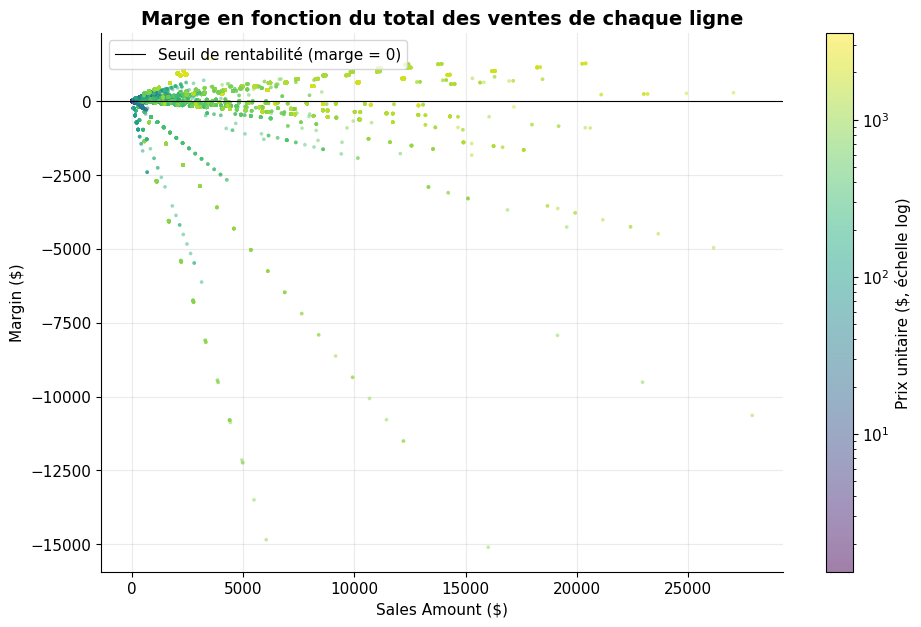

In [30]:
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(figsize=(11, 7))
nuage = ax.scatter(sales['Sales Amount'], sales['Margin'], c=sales['Unit Price'],
                   cmap='viridis', norm=LogNorm(), s=7, alpha=0.5, linewidths=0)
cbar = fig.colorbar(nuage, ax=ax)
cbar.set_label("Prix unitaire ($, échelle log)")
ax.axhline(0, color='black', lw=0.8)
ax.set_title("Marge en fonction du total des ventes de chaque ligne")
ax.set_xlabel("Sales Amount ($)")
ax.set_ylabel("Margin ($)")
ax.legend(handles=[plt.Line2D([], [], color='black', lw=0.8)], labels=["Seuil de rentabilité (marge = 0)"], loc='upper left')
fig.savefig(f"{FIG_DIR}/scatter_ventes_marge.png")
plt.show()

> **Lecture** : les gains par ligne sont plafonnés (maximum d'environ +1 490 $) alors que les pertes peuvent atteindre -15 100 $. Les « éventails » de points descendants correspondent à des produits vendus sous leur coût standard : plus la quantité est grande, plus la perte grandit. Les lignes à prix unitaire élevé (jaune) sont aussi celles qui portent les plus gros gains, mais aussi une bonne partie des plus grosses pertes.

### 6.2 Diagrammes à moustaches : une boîte par territoire, valeurs = ventes par modèle de produit

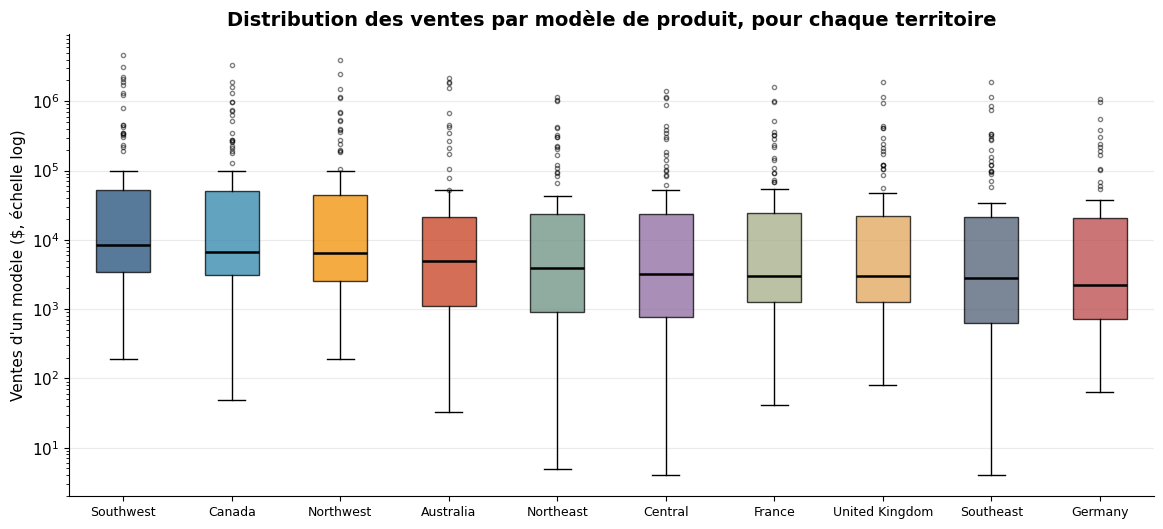

In [31]:
# Pour chaque territoire : une valeur par modèle de produit (somme des ventes du modèle dans ce territoire)
vm_terr = sales_e.groupby(['Region', 'Model'])['Sales Amount'].sum().reset_index()
ordre = vm_terr.groupby('Region')['Sales Amount'].median().sort_values(ascending=False).index
donnees = [vm_terr.loc[vm_terr['Region'] == r, 'Sales Amount'].to_numpy() for r in ordre]

fig, ax = plt.subplots(figsize=(14, 6))
bp = ax.boxplot(donnees, tick_labels=ordre, patch_artist=True, medianprops=dict(color='black', lw=1.8),
                flierprops=dict(marker='o', markersize=3, alpha=0.5))
for boite, couleur in zip(bp['boxes'], PALETTE):
    boite.set_facecolor(couleur); boite.set_alpha(0.75)
ax.set_yscale('log')                                  # distribution très asymétrique
ax.set_title("Distribution des ventes par modèle de produit, pour chaque territoire")
ax.set_ylabel("Ventes d'un modèle ($, échelle log)")
ax.tick_params(axis='x', labelrotation=0, labelsize=9)
ax.grid(axis='x', visible=False)
fig.savefig(f"{FIG_DIR}/boxplot_territoires.png")
plt.show()

### 6.3 Barres avec valeurs : ventes et marge par catégorie

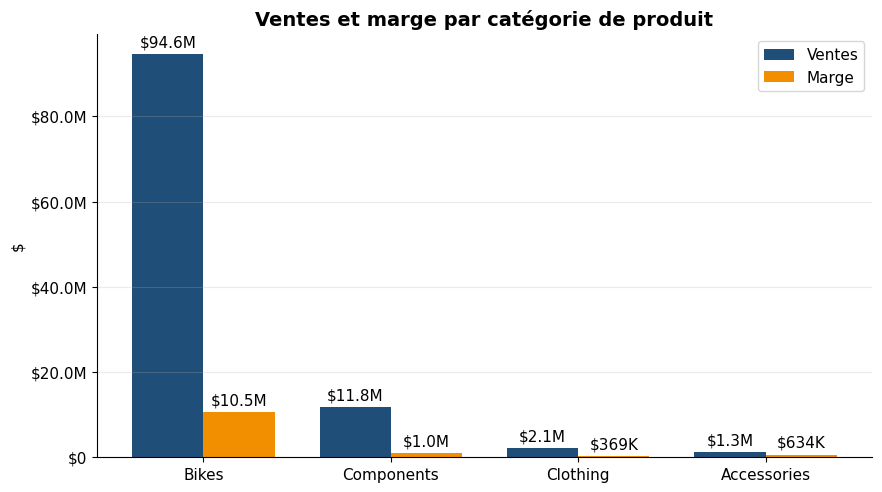

In [32]:
cat = sales_e.groupby('Category').agg(ventes=('Sales Amount', 'sum'), marge=('Margin', 'sum')).sort_values('ventes', ascending=False)

x = np.arange(len(cat)); largeur = 0.38
fig, ax = plt.subplots(figsize=(10, 5.5))
b1 = ax.bar(x - largeur/2, cat['ventes'], largeur, label="Ventes", color=PALETTE[0])
b2 = ax.bar(x + largeur/2, cat['marge'],  largeur, label="Marge",  color=PALETTE[2])
ax.bar_label(b1, labels=[fmt_usd(v) for v in cat['ventes']], padding=3)
ax.bar_label(b2, labels=[fmt_usd(v) for v in cat['marge']],  padding=3)
ax.set_xticks(x, cat.index)
ax.set_title("Ventes et marge par catégorie de produit")
ax.set_ylabel("$")
ax.yaxis.set_major_formatter(lambda v, _: fmt_usd(v))
ax.legend()
ax.grid(axis='x', visible=False)
plt.show()

### 6.4 Matrice de corrélation (heat map)

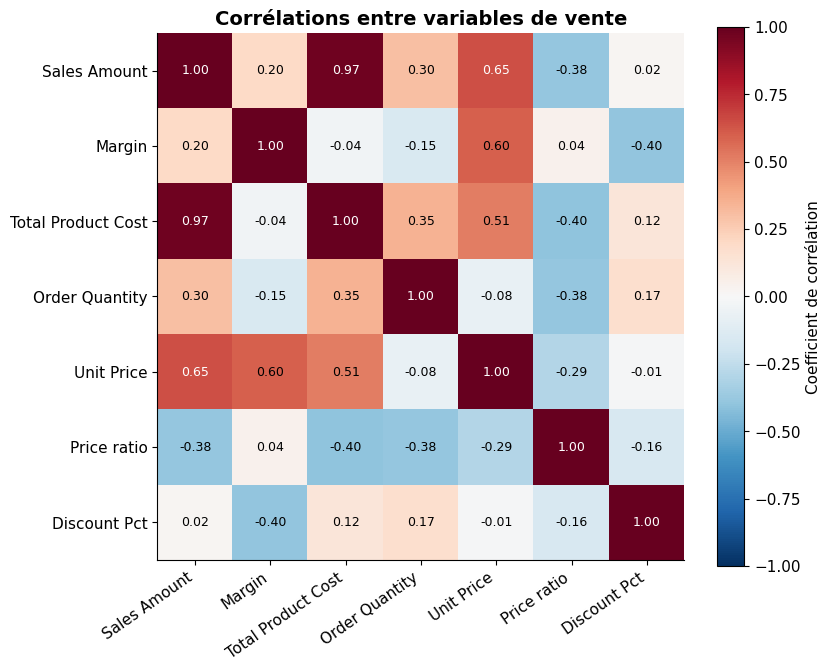

Corrélation ventes / marge : 0.201


In [33]:
cols_corr = ['Sales Amount', 'Margin', 'Total Product Cost', 'Order Quantity', 'Unit Price', 'Price ratio', 'Discount Pct']
corr = sales[cols_corr].corr()

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols_corr)), cols_corr, rotation=35, ha='right')
ax.set_yticks(range(len(cols_corr)), cols_corr)
ax.grid(False)
for i in range(len(cols_corr)):
    for j in range(len(cols_corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha='center', va='center',
                color='white' if abs(corr.iloc[i, j]) > 0.6 else 'black', fontsize=9)
fig.colorbar(im, ax=ax, label="Coefficient de corrélation")
ax.set_title("Corrélations entre variables de vente")
fig.savefig(f"{FIG_DIR}/heatmap_correlations.png")
plt.show()
print(f"Corrélation ventes / marge : {corr.loc['Sales Amount', 'Margin']:.3f}")

> **Lecture** : `Sales Amount` et `Total Product Cost` sont presque identiques (0,97). La marge est surtout liée au prix unitaire (0,60) et très peu au montant de la vente (0,20). La quantité est même légèrement négative avec la marge (-0,15) : ce qui est cohérent avec des prix ou des remises moins favorables sur les gros volumes (hypothèse à vérifier).

### 6.5 Parts de marché (secteurs)

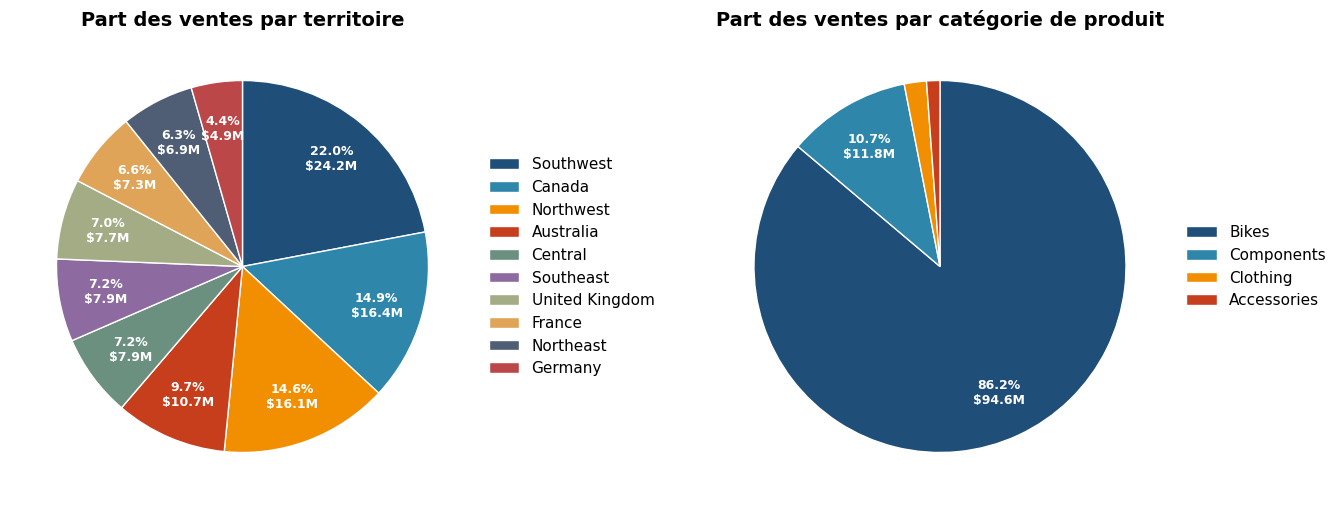

In [34]:
def autopct_usd(valeurs, seuil=3):
    """Affiche '12.3%\n$4.5M' dans le secteur, sauf pour les très petits secteurs."""
    total = np.sum(valeurs)
    def f(pct):
        return "" if pct < seuil else f"{pct:.1f}%\n{fmt_usd(pct * total / 100)}"
    return f

part_terr = sales_e.groupby('Region')['Sales Amount'].sum().sort_values(ascending=False)
part_cat  = sales_e.groupby('Category')['Sales Amount'].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, serie, titre in [(axes[0], part_terr, "Part des ventes par territoire"),
                         (axes[1], part_cat,  "Part des ventes par catégorie de produit")]:
    ax.pie(serie, autopct=autopct_usd(serie.values), startangle=90, counterclock=False,
           colors=PALETTE[:len(serie)], pctdistance=0.75, textprops=dict(color='white', fontsize=9, weight='bold'),
           wedgeprops=dict(edgecolor='white'))
    ax.legend(serie.index, loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False)
    ax.set_title(titre)
fig.subplots_adjust(wspace=0.5)
fig.savefig(f"{FIG_DIR}/secteurs_parts.png")
plt.show()

## 7. Analyse temporelle des ventes

In [35]:
ventes_dt = sales.set_index('OrderDate')['Sales Amount']          # série dont l'index est une date
mensuel     = ventes_dt.resample('MS').sum()
trimestriel = ventes_dt.resample('QE').sum()
annuel      = ventes_dt.resample('YE').sum()
fiscal      = sales.groupby('Fiscal Year')['Sales Amount'].sum()

print("Ventes mensuelles (début) :"); display(mensuel.head(3).to_frame('Sales'))
print("Ventes par année civile :");  display(annuel.to_frame('Sales').set_axis(annuel.index.year))
print("Ventes par année fiscale :"); display(fiscal.to_frame('Sales'))
print("Dernière commande :", sales['OrderDate'].max().date(), "-> juin 2020, 2017 et l'année civile 2020 sont incomplètes")

Ventes mensuelles (début) :


,Sales
OrderDate,
2017-07-01,1.423357e+06
2017-08-01,2.057902e+06
2017-09-01,2.523948e+06


Ventes par année civile :


,Sales
OrderDate,
2017,1.192856e+07
2018,3.051689e+07
2019,4.289511e+07
2020,2.446872e+07


Ventes par année fiscale :


,Sales
Fiscal Year,
FY2018,2.386089e+07
FY2019,3.407011e+07
FY2020,5.187827e+07


Dernière commande : 2020-06-15 -> juin 2020, 2017 et l'année civile 2020 sont incomplètes


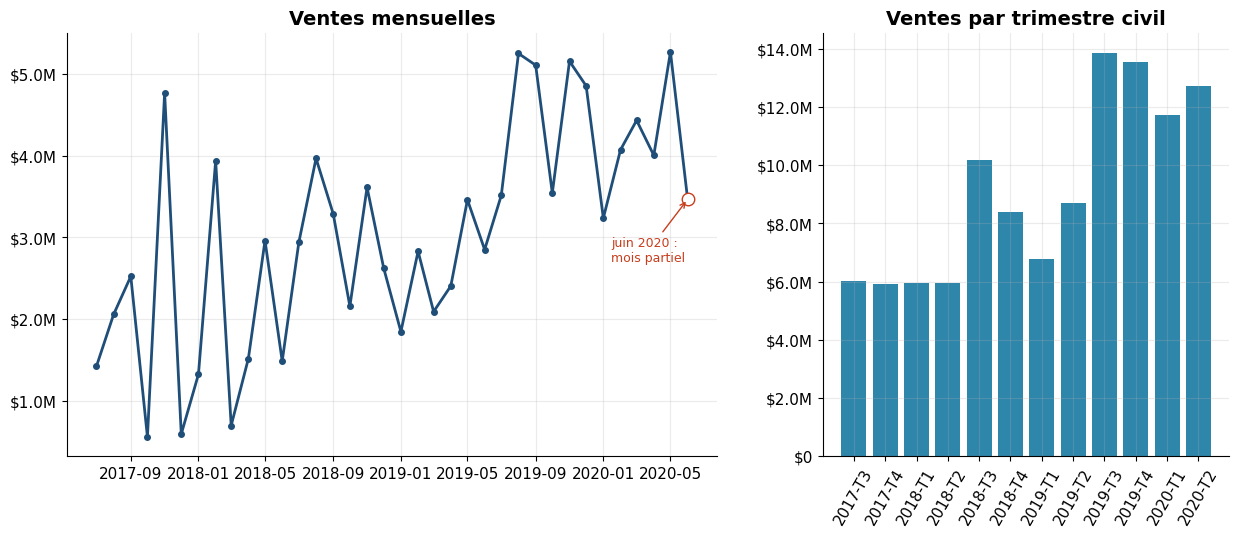

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw=dict(width_ratios=[1.6, 1]))

axes[0].plot(mensuel.index, mensuel.values, marker='o', ms=4, color=PALETTE[0], lw=2)
axes[0].plot(mensuel.index[-1], mensuel.values[-1], marker='o', ms=9, mfc='white', color=PALETTE[3], ls='')
axes[0].annotate("juin 2020 :\nmois partiel", (mensuel.index[-1], mensuel.values[-1]),
                 textcoords='offset points', xytext=(-55, -45), fontsize=9, color=PALETTE[3],
                 arrowprops=dict(arrowstyle='->', color=PALETTE[3]))
axes[0].set_title("Ventes mensuelles")
axes[0].yaxis.set_major_formatter(lambda v, _: fmt_usd(v))

lab_t = [f"{d.year}-T{d.quarter}" for d in trimestriel.index]
axes[1].bar(lab_t, trimestriel.values, color=PALETTE[1])
axes[1].set_xticks(range(len(lab_t)), lab_t, rotation=60)
axes[1].set_title("Ventes par trimestre civil")
axes[1].yaxis.set_major_formatter(lambda v, _: fmt_usd(v))
plt.show()

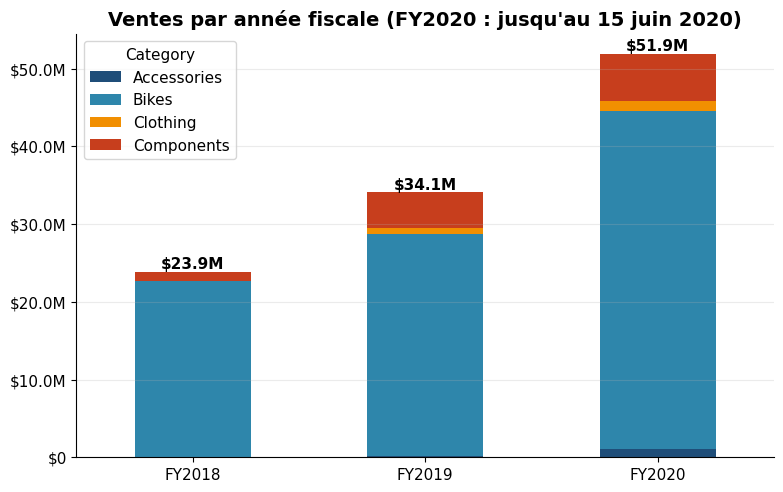

In [37]:
# Ventes par année fiscale, avec la répartition par catégorie
fy_cat = sales_e.assign(FY=sales['Fiscal Year']).pivot_table(values='Sales Amount', index='FY', columns='Category', aggfunc='sum')

ax = fy_cat.plot(kind='bar', stacked=True, figsize=(9, 5.5), color=PALETTE[:fy_cat.shape[1]], rot=0)
for i, total in enumerate(fy_cat.sum(axis=1)):
    ax.text(i, total, fmt_usd(total), ha='center', va='bottom', fontweight='bold')
ax.set_title("Ventes par année fiscale (FY2020 : jusqu'au 15 juin 2020)")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(lambda v, _: fmt_usd(v))
ax.grid(axis='x', visible=False)
plt.show()

### Graphique en bougies (candlestick) des ventes quotidiennes, par mois

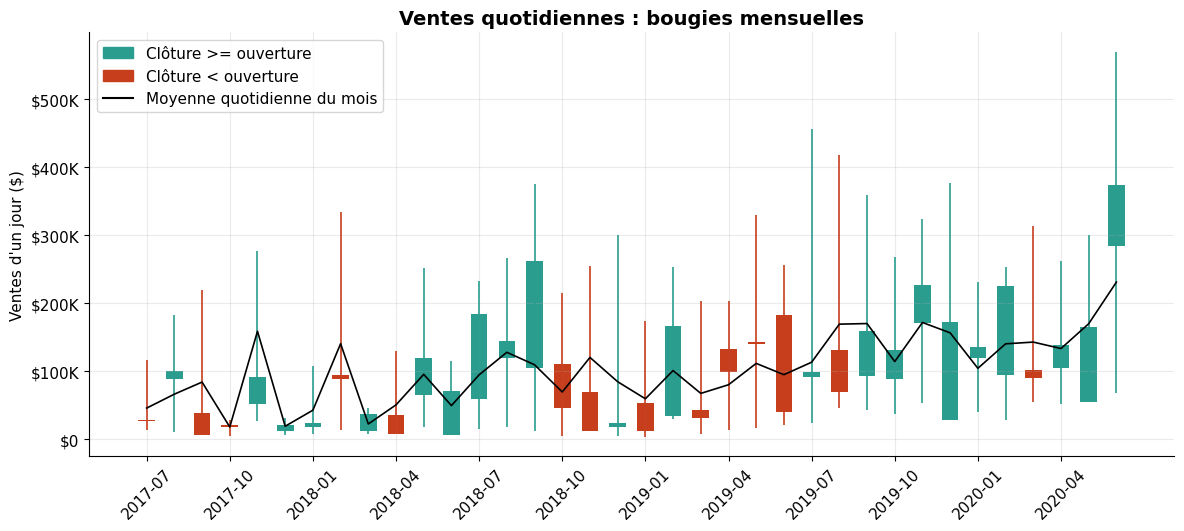

In [38]:
# Chaque bougie résume un mois : ouverture = ventes du 1er jour, clôture = ventes du dernier jour,
# mèche haute / basse = meilleur / pire jour du mois. Dessiné avec Matplotlib seul (pas de dépendance en plus).
groupe_mois = quotidien['Sales'].groupby(quotidien.index.to_period('M'))
ohlc = pd.DataFrame({'open': groupe_mois.first(), 'high': groupe_mois.max(),
                     'low': groupe_mois.min(),   'close': groupe_mois.last()})
x = np.arange(len(ohlc))
hausse = (ohlc['close'] >= ohlc['open']).to_numpy()
couleurs = np.where(hausse, '#2a9d8f', '#c73e1d')

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.vlines(x, ohlc['low'], ohlc['high'], colors=couleurs, lw=1.2)
ax.bar(x, (ohlc['close'] - ohlc['open']).to_numpy(), bottom=ohlc['open'].to_numpy(), width=0.6, color=couleurs)
ax.plot(x, groupe_mois.mean().to_numpy(), color='black', lw=1.2, label="Moyenne quotidienne du mois")
ax.set_xticks(x[::3], [str(p) for p in ohlc.index[::3]], rotation=45)
ax.set_title("Ventes quotidiennes : bougies mensuelles")
ax.set_ylabel("Ventes d'un jour ($)")
ax.yaxis.set_major_formatter(lambda v, _: fmt_usd(v))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#2a9d8f'), plt.Rectangle((0, 0), 1, 1, color='#c73e1d'),
                   plt.Line2D([], [], color='black')],
          labels=["Clôture >= ouverture", "Clôture < ouverture", "Moyenne quotidienne du mois"], loc='upper left')
fig.savefig(f"{FIG_DIR}/bougies_mensuelles.png")
plt.show()

> **Lecture** :
> - Par année fiscale (juillet → juin), les ventes passent de 23,9 M$ (FY2018) à 34,1 M$ (FY2019, +43 %) puis 51,9 M$ (FY2020, +52 %, données jusqu'au 15 juin 2020).
> - Les bougies mensuelles montrent une volatilité quotidienne croissante : un mois peut contenir des journées à quelques milliers de dollars et d'autres à plus de 300 000 $.
> - Attention aux périodes incomplètes : 2017 (6 mois), 2020 (5,5 mois) et juin 2020 (15 jours). Les comparaisons par année civile sont donc trompeuses, d'où l'usage de l'année fiscale.

## 8. Fusion des données pour une analyse globale

In [39]:
clients = customers.rename(columns={
    'Customer ID': 'Customer ID', 'Customer': 'Customer Name', 'City': 'Customer City',
    'State-Province': 'Customer State', 'Country-Region': 'Customer Country', 'Postal Code': 'Customer Postal Code'})
revendeurs = resellers.rename(columns={
    'City': 'Reseller City', 'State-Province': 'Reseller State',
    'Country-Region': 'Reseller Country', 'Postal Code': 'Reseller Postal Code'})

full = (sales
    .merge(orders[['SalesOrderLineKey', 'Channel', 'Sales Order', 'Sales Order Line', 'Line number']],
           on='SalesOrderLineKey', how='left', validate='one_to_one')
    .merge(products[['ProductKey', 'SKU', 'Product', 'Color', 'List Price', 'Model', 'Subcategory', 'Category']],
           on='ProductKey', how='left', validate='many_to_one')
    .merge(territories, on='SalesTerritoryKey', how='left', validate='many_to_one')
    .merge(clients,     on='CustomerKey',  how='left', validate='many_to_one')
    .merge(revendeurs,  on='ResellerKey',  how='left', validate='many_to_one')
    .merge(dates[['DateKey', 'MonthKey']].rename(columns={'DateKey': 'OrderDateKey'}),
           on='OrderDateKey', how='left', validate='many_to_one')
)
print("Dimensions :", full.shape)

Dimensions : (121253, 53)


In [40]:
# Contrôles : aucune ligne de vente perdue ou dupliquée, aucun montant modifié
assert len(full) == len(sales), "des lignes ont été perdues ou dupliquées"
assert full['SalesOrderLineKey'].is_unique
assert np.isclose(full['Sales Amount'].sum(), sales['Sales Amount'].sum())
cles_dim = ['Channel', 'Product', 'Region', 'Customer Name', 'Reseller', 'MonthKey']
print(f"Lignes : sales = {len(sales):,} | résultat = {len(full):,}")
print("Valeurs vides dans les colonnes issues des jointures :")
print(full[cles_dim].isna().sum().to_string())
print()
print("Répartition par canal (clé -1 = pas de client / pas de revendeur) :")
print(pd.crosstab(full['Channel'], [full['CustomerKey'] == -1, full['ResellerKey'] == -1],
                  rownames=['Canal'], colnames=['sans client', 'sans revendeur']))

Lignes : sales = 121,253 | résultat = 121,253
Valeurs vides dans les colonnes issues des jointures :
Channel          0
Product          0
Region           0
Customer Name    0
Reseller         0
MonthKey         0

Répartition par canal (clé -1 = pas de client / pas de revendeur) :
sans client     False  True 
sans revendeur  True   False
Canal                       
Internet        60398      0
Reseller            0  60855


### Analyse croisée

In [41]:
# Ventes par produit (top 10) et par territoire
top_produits = full.groupby('Product')['Sales Amount'].sum().nlargest(10).index
pivot_p_t = (full[full['Product'].isin(top_produits)]
             .pivot_table(values='Sales Amount', index='Product', columns='Region', aggfunc='sum', fill_value=0, margins=True, margins_name='Total'))
display((trier_pivot(pivot_p_t) / 1e3).round(0))    # en milliers de $

Region,Australia,Canada,Central,France,Germany,Northeast,Northwest,Southeast,Southwest,United Kingdom,Total
Product,,,,,,,,,,,
"Mountain-200 Black, 38",370.0,736.0,249.0,380.0,153.0,188.0,779.0,300.0,870.0,376.0,4401.0
"Mountain-200 Black, 42",395.0,642.0,245.0,293.0,129.0,219.0,679.0,182.0,836.0,390.0,4009.0
"Mountain-200 Silver, 38",394.0,523.0,230.0,234.0,191.0,201.0,592.0,227.0,783.0,319.0,3694.0
"Mountain-200 Silver, 42",351.0,481.0,233.0,262.0,145.0,215.0,623.0,154.0,695.0,280.0,3438.0
"Mountain-200 Silver, 46",316.0,503.0,225.0,236.0,185.0,193.0,615.0,176.0,681.0,305.0,3434.0
"Mountain-200 Black, 46",346.0,415.0,207.0,220.0,181.0,152.0,656.0,117.0,757.0,260.0,3310.0
"Road-250 Black, 44",245.0,371.0,209.0,197.0,89.0,263.0,213.0,153.0,561.0,218.0,2517.0
"Road-250 Black, 48",303.0,308.0,182.0,192.0,72.0,203.0,197.0,140.0,550.0,201.0,2348.0
"Road-250 Black, 52",332.0,269.0,164.0,147.0,102.0,110.0,140.0,106.0,454.0,189.0,2012.0


In [42]:
# Nombre de produits par modèle (catalogue)
produits_par_modele = products.groupby('Model').size().sort_values(ascending=False)
print(f"{len(produits_par_modele)} modèles pour {len(products)} produits")
display(produits_par_modele.head(10).to_frame('nb_produits'))
print("Répartition :"); display(produits_par_modele.value_counts().sort_index().to_frame('nb_modeles').rename_axis('produits_par_modele'))

119 modèles pour 397 produits


,nb_produits
Model,
LL Road Frame,30
HL Road Frame,25
Road-650,24
HL Mountain Frame,22
Road-250,13
Mountain-200,12
Long-Sleeve Logo Jersey,12
Road-550-W,10
Touring-3000,10


Répartition :


,nb_modeles
produits_par_modele,
1,75
2,8
3,7
4,7
5,4
6,1
8,3
9,1
10,6


In [43]:
# Clients : on exclut la clé -1 ("[Not Applicable]" = ventes via revendeurs)
ventes_clients = full[full['CustomerKey'] != -1]

plus_commandes = (ventes_clients.groupby(['CustomerKey', 'Customer Name'])['Sales Order'].nunique()
                  .nlargest(10).to_frame('nb_commandes'))
print("Clients avec le plus de commandes :"); display(plus_commandes)

plus_depense = (ventes_clients.groupby(['CustomerKey', 'Customer Name'])['Sales Amount'].sum()
                .nlargest(10).round(0).to_frame('total_depense'))
print("Clients ayant le plus dépensé :"); display(plus_depense)
print(f"Clients distincts : {ventes_clients['CustomerKey'].nunique():,}")

Clients avec le plus de commandes :


,,nb_commandes
CustomerKey,Customer Name,
11091,Dalton Perez,28
11176,Mason Roberts,28
11185,Ashley Henderson,27
11200,Jason Griffin,27
11223,Hailey Patterson,27
11262,Jennifer Simmons,27
11276,Nancy Chapman,27
11277,Charles Jackson,27
11287,Henry Garcia,27


Clients ayant le plus dépensé :


,,total_depense
CustomerKey,Customer Name,
12301,Nichole Nara,13295.0
12132,Kaitlyn Henderson,13294.0
12308,Margaret He,13269.0
12131,Randall Dominguez,13266.0
12300,Adriana Gonzalez,13243.0
12321,Rosa Hu,13216.0
12124,Brandi Gill,13196.0
12307,Brad She,13173.0
12296,Francisco Sara,13165.0


Clients distincts : 18,484


In [44]:
# Nombre de ventes (lignes de commande) par catégorie de produit et par territoire
display(pd.crosstab(full['Category'], full['Region'], margins=True, margins_name='Total'))

Region,Australia,Canada,Central,France,Germany,Northeast,Northwest,Southeast,Southwest,United Kingdom,Total
Category,,,,,,,,,,,
Accessories,7178,6392,500,3668,3518,485,6176,498,8386,4392,41193
Bikes,5241,5366,2569,2618,2229,2445,5187,2560,8605,3185,40005
Clothing,2152,3872,1148,1577,1180,1100,2873,1261,4455,1750,21368
Components,487,3434,1615,1225,537,1806,2629,1657,4198,1099,18687
Total,15058,19064,5832,9088,7464,5836,16865,5976,25644,10426,121253


### Rentabilité par canal de vente

In [45]:
canal = (full.groupby('Channel', observed=True)
         .agg(ventes=('Sales Amount', 'sum'), marge=('Margin', 'sum'), lignes=('SalesOrderLineKey', 'count'),
              lignes_a_perte=('Margin', lambda m: (m < 0).sum()))
         .assign(part_ventes=lambda d: d['ventes'] / d['ventes'].sum(),
                 taux_marge=lambda d: d['marge'] / d['ventes'],
                 part_lignes_a_perte=lambda d: d['lignes_a_perte'] / d['lignes']))
display(canal.round(3))

canal_cat = (full.groupby(['Channel', 'Category'], observed=True)
             .agg(ventes=('Sales Amount', 'sum'), marge=('Margin', 'sum'))
             .assign(taux_marge=lambda d: d['marge'] / d['ventes']))
display(canal_cat.round(3))

# Lignes dont le prix de vente unitaire est inférieur au coût standard
sous_cout = full[full['Unit Price'] < full['Product Standard Cost']]
print(f"Lignes vendues sous le coût standard : {len(sous_cout):,} ({len(sous_cout) / len(full):.0%}), "
      f"marge cumulée {sous_cout['Margin'].sum():,.0f} $")

,ventes,marge,lignes,lignes_a_perte,part_ventes,taux_marge,part_lignes_a_perte
Channel,,,,,,,
Internet,2.935868e+07,1.208088e+07,60398,0,0.267,0.411,0.000
Reseller,8.045060e+07,4.704826e+05,60855,21829,0.733,0.006,0.359


ventes         marge  taux_marge
Channel  Category                                           
Internet Accessories  7.007600e+05  4.386746e+05       0.626
         Bikes        2.831814e+07  1.150580e+07       0.406
         Clothing     3.397726e+05  1.364126e+05       0.401
Reseller Accessories  5.712979e+05  1.957926e+05       0.343
         Bikes        6.630238e+07 -9.906999e+05      -0.015
         Clothing     1.777841e+06  2.324234e+05       0.131
         Components   1.179908e+07  1.032966e+06       0.088

Lignes vendues sous le coût standard : 21,821 (18%), marge cumulée -3,314,614 $


### Visualisations globales (produit × territoire × période)

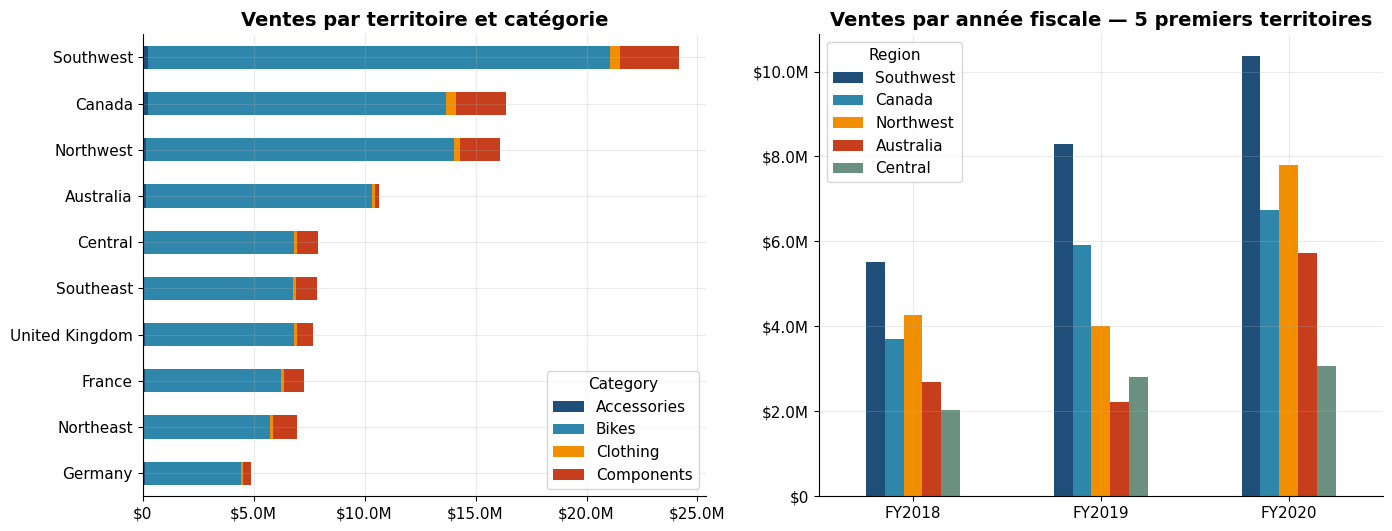

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Territoire x catégorie
t_c = full.pivot_table(values='Sales Amount', index='Region', columns='Category', aggfunc='sum').loc[
        full.groupby('Region')['Sales Amount'].sum().sort_values().index]
t_c.plot(kind='barh', stacked=True, ax=axes[0], color=PALETTE[:t_c.shape[1]])
axes[0].set_title("Ventes par territoire et catégorie")
axes[0].set_ylabel("")
axes[0].xaxis.set_major_formatter(lambda v, _: fmt_usd(v))

# Année fiscale x territoire (top 5 territoires)
top5 = full.groupby('Region')['Sales Amount'].sum().nlargest(5).index
a_t = full[full['Region'].isin(top5)].pivot_table(values='Sales Amount', index='Fiscal Year', columns='Region', aggfunc='sum')[list(top5)]
a_t.plot(kind='bar', ax=axes[1], color=PALETTE[:5], rot=0)
axes[1].set_title("Ventes par année fiscale — 5 premiers territoires")
axes[1].set_xlabel("")
axes[1].yaxis.set_major_formatter(lambda v, _: fmt_usd(v))
plt.show()

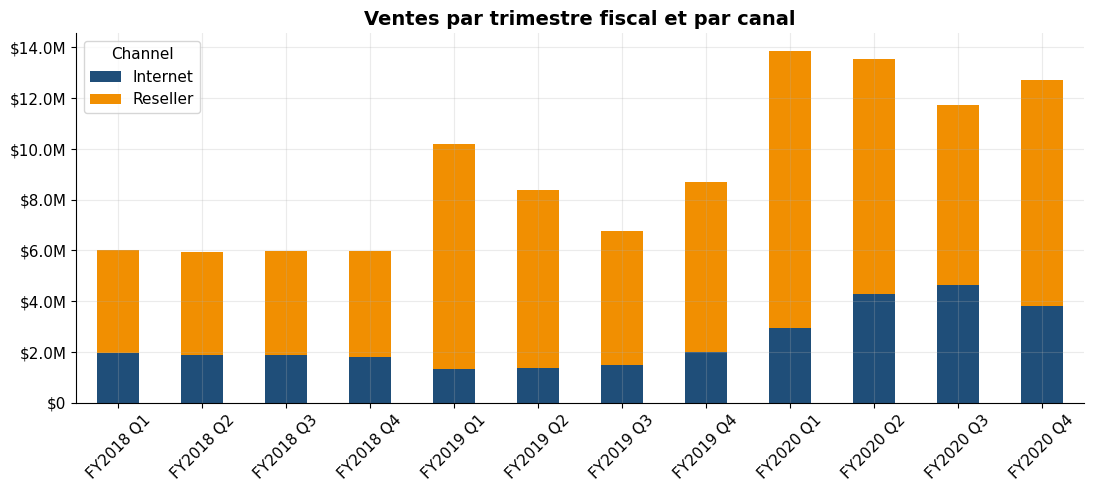

In [47]:
# Canal de vente x période
c_p = full.pivot_table(values='Sales Amount', index='Fiscal Quarter', columns='Channel', aggfunc='sum', observed=True)
ax = c_p.plot(kind='bar', stacked=True, figsize=(13, 4.8), color=[PALETTE[0], PALETTE[2]], rot=45)
ax.set_title("Ventes par trimestre fiscal et par canal")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(lambda v, _: fmt_usd(v))
plt.show()

> **Lecture** : la fusion conserve bien les 121 253 lignes de ventes, sans doublon ni perte de montant. Le jeu de données est coupé en deux canaux parfaitement séparés : `Reseller` (clé client -1) et `Internet` (clé revendeur -1), avec environ 60 000 lignes chacun.
>
> **Point clé pour la décision** : les revendeurs font 73 % du chiffre d'affaires mais seulement **0,6 % de marge** (36 % de leurs lignes sont vendues sous le coût standard), alors que le canal Internet génère **41 % de marge** et **96 % de la marge totale** avec 27 % des ventes. La marge négative du canal revendeurs est concentrée sur les vélos (-1,5 %).
> **Réserve** : cette marge est calculée avec le *coût standard* du catalogue, pas avec un coût réel d'achat ou de production à la date de la vente. À vérifier avant toute décision.

## 9. Analyse des performances des revendeurs

In [48]:
rev = full[full['ResellerKey'] != -1]
perf_rev = (rev.groupby(['ResellerKey', 'Reseller', 'Business Type', 'Reseller Country'])
            .agg(ventes=('Sales Amount', 'sum'), marge=('Margin', 'sum'), commandes=('Sales Order', 'nunique'))
            .assign(taux_marge=lambda d: d['marge'] / d['ventes'])
            .sort_values('ventes', ascending=False))
print(f"{len(perf_rev)} revendeurs actifs, {rev['Sales Amount'].sum() / full['Sales Amount'].sum():.0%} du chiffre d'affaires total")
display(perf_rev.head(10).round(3))
print(f"Les 10 premiers revendeurs pèsent {perf_rev['ventes'].head(10).sum() / perf_rev['ventes'].sum():.1%} du chiffre d'affaires revendeurs : la base est très diffuse.")

635 revendeurs actifs, 73% du chiffre d'affaires total


,,,,ventes,marge,commandes,taux_marge
ResellerKey,Reseller,Business Type,Reseller Country,,,,
697,Brakes and Gears,Value Added Reseller,United States,877107.192,62737.636,12,0.072
170,Excellent Riding Supplies,Value Added Reseller,United States,853849.180,-19428.980,12,-0.023
678,Vigorous Exercise Company,Warehouse,Canada,841908.771,2130.251,12,0.003
328,Totes & Baskets Company,Value Added Reseller,United States,816755.576,-18639.522,12,-0.023
514,Retail Mall,Warehouse,Canada,799277.895,-22993.418,12,-0.029
155,Corner Bicycle Supply,Value Added Reseller,Canada,787773.044,-13782.511,12,-0.017
72,Outdoor Equipment Store,Warehouse,United States,746317.529,-27918.470,8,-0.037
433,Thorough Parts and Repair Services,Value Added Reseller,United States,740985.834,-24512.872,12,-0.033
227,"Health Spa, Limited",Warehouse,Canada,730798.714,-26332.817,12,-0.036


Les 10 premiers revendeurs pèsent 9.8% du chiffre d'affaires revendeurs : la base est très diffuse.


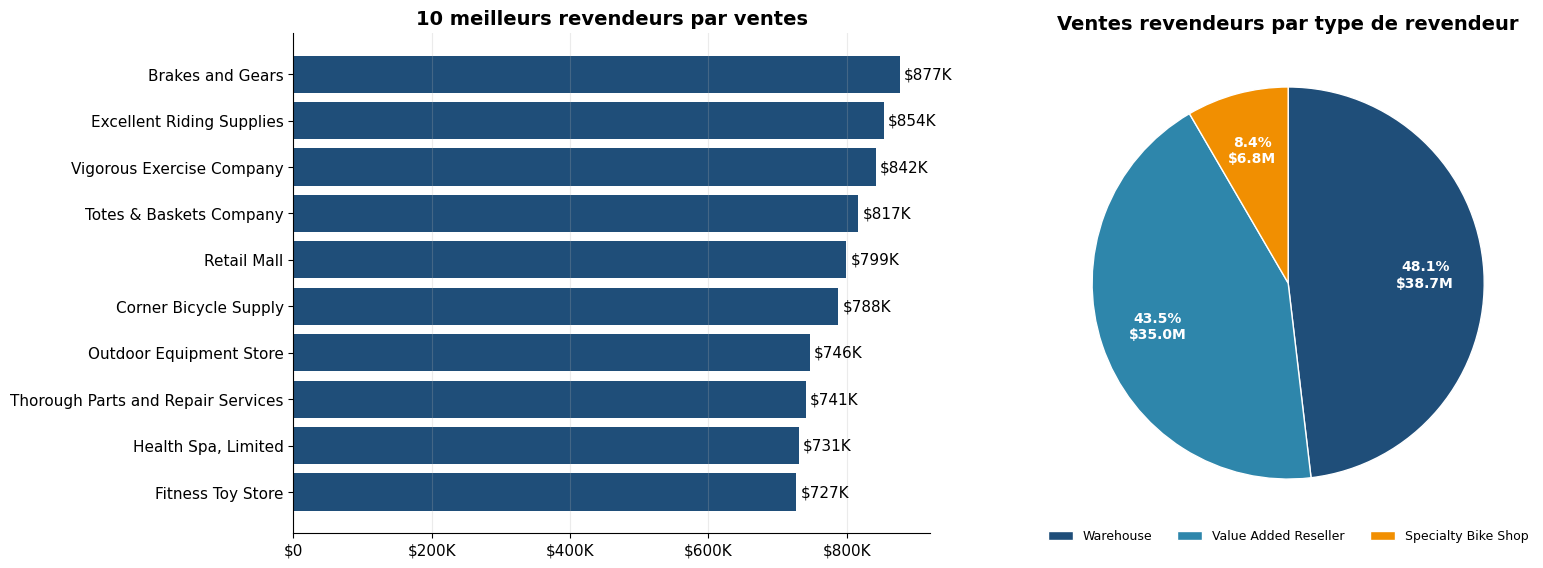

In [49]:
top10 = perf_rev.head(10).reset_index().iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw=dict(width_ratios=[1.3, 1]))

b = axes[0].barh(top10['Reseller'], top10['ventes'], color=PALETTE[0])
axes[0].bar_label(b, labels=[fmt_usd(v) for v in top10['ventes']], padding=3)
axes[0].set_title("10 meilleurs revendeurs par ventes")
axes[0].xaxis.set_major_formatter(lambda v, _: fmt_usd(v))
axes[0].grid(axis='y', visible=False)

# Répartition du chiffre d'affaires revendeurs par type de revendeur
par_type = perf_rev.groupby('Business Type')['ventes'].sum().sort_values(ascending=False)
axes[1].pie(par_type, autopct=autopct_usd(par_type.values, seuil=2), startangle=90, counterclock=False,
            colors=PALETTE[:len(par_type)], pctdistance=0.7,
            textprops=dict(color='white', fontsize=10, weight='bold'), wedgeprops=dict(edgecolor='white'))
axes[1].legend(par_type.index, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=len(par_type), frameon=False, fontsize=9)
axes[1].set_title("Ventes revendeurs par type de revendeur")
fig.savefig(f"{FIG_DIR}/revendeurs.png")
plt.show()

Fiscal Year,FY2018,FY2019,FY2020,Croissance FY19 vs FY18,Croissance FY20 vs FY19
Reseller,,,,,
Brakes and Gears,185995.56,293874.39,397237.24,0.58,0.35
Excellent Riding Supplies,180664.82,396454.93,276729.43,1.19,-0.30
Vigorous Exercise Company,300525.66,285632.59,255750.52,-0.05,-0.10
Totes & Baskets Company,167106.04,359872.04,289777.50,1.15,-0.19
Retail Mall,188175.23,370636.45,240466.22,0.97,-0.35
Corner Bicycle Supply,171109.15,366058.22,250605.68,1.14,-0.32
Outdoor Equipment Store,NaN,431654.97,314662.56,NaN,-0.27
Thorough Parts and Repair Services,172249.77,181777.87,386958.19,0.06,1.13
"Health Spa, Limited",146247.72,321732.71,262818.28,1.20,-0.18


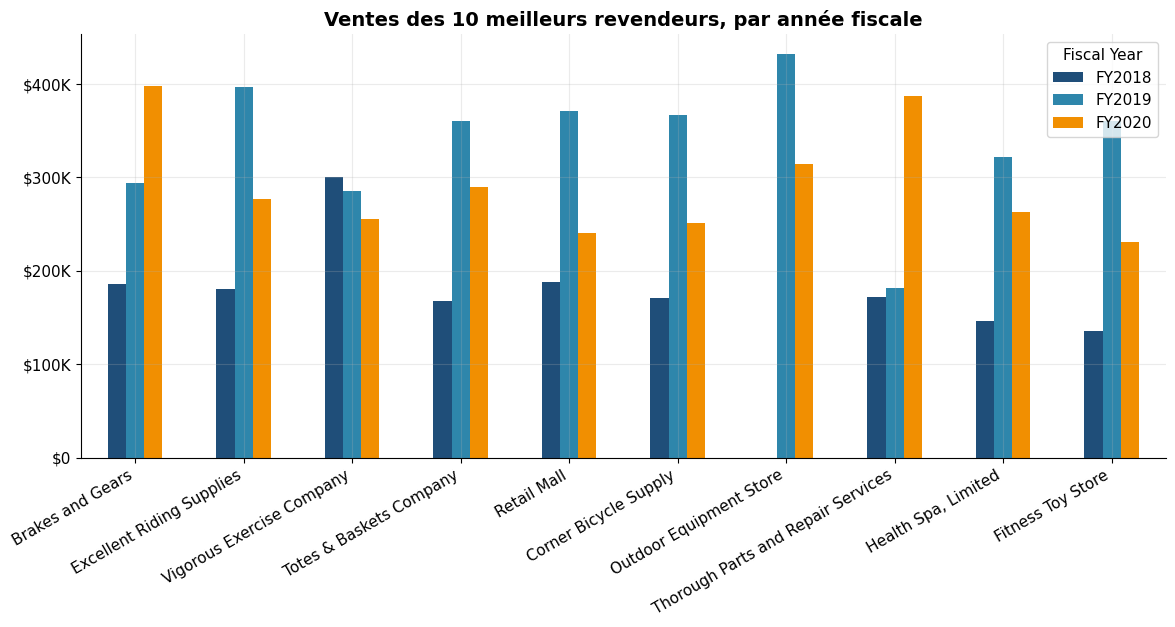

Chiffre d'affaires revendeurs par année fiscale :


,Sales
Fiscal Year,
FY2018,1.628844e+07
FY2019,2.792167e+07
FY2020,3.624048e+07


In [50]:
# Comparaison des performances sur différentes périodes (années fiscales)
noms_top = perf_rev.head(10).index.get_level_values('Reseller')
rev_fy = (rev[rev['Reseller'].isin(noms_top)]
          .pivot_table(values='Sales Amount', index='Reseller', columns='Fiscal Year', aggfunc='sum')
          .loc[noms_top])
rev_fy['Croissance FY19 vs FY18'] = rev_fy['FY2019'] / rev_fy['FY2018'] - 1
rev_fy['Croissance FY20 vs FY19'] = rev_fy['FY2020'] / rev_fy['FY2019'] - 1
display(rev_fy.round(2))

ax = rev_fy[['FY2018', 'FY2019', 'FY2020']].plot(kind='bar', figsize=(14, 5.5), color=PALETTE[:3], rot=30)
ax.set_title("Ventes des 10 meilleurs revendeurs, par année fiscale")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(lambda v, _: fmt_usd(v))
plt.xticks(ha='right')
plt.show()

# Évolution du chiffre d'affaires de l'ensemble des revendeurs
tous_fy = rev.groupby('Fiscal Year')['Sales Amount'].sum()
print("Chiffre d'affaires revendeurs par année fiscale :"); display(tous_fy.to_frame('Sales'))

> **Lecture** :
> - La base revendeurs est très diffuse : 635 revendeurs actifs, et les 10 premiers ne pèsent qu'environ 10 % du chiffre d'affaires revendeurs. Aucun revendeur n'est vraiment critique pris isolément.
> - Plusieurs des meilleurs revendeurs ont une marge négative (par exemple `Excellent Riding Supplies` : -2,3 %). Être « performant » en ventes ne veut donc pas dire rentable.
> - Dans le top 10, 8 revendeurs sur 10 reculent en FY2020 par rapport à FY2019 (de -10 % à -36 %), alors que le total revendeurs progresse de 30 %. La croissance semble donc venir du reste de la base. Les deux exceptions sont `Brakes and Gears` (+35 %) et `Thorough Parts and Repair Services` (+113 %).
> - Par type, la répartition en secteurs ci-dessus montre le poids de chaque catégorie de revendeur dans le chiffre d'affaires.

## 10. Présentation — le point de vue d'un bureau de décision

### Ce que disent les données
| Constat | Chiffres clés |
|---|---|
| **Forte croissance** | Ventes de 23,9 M$ (FY2018) → 34,1 M$ (FY2019) → 51,9 M$ (FY2020, jusqu'au 15 juin) |
| **Rentabilité très inégale selon le canal** | Revendeurs : 73 % des ventes, 0,6 % de marge. Internet : 27 % des ventes, 41 % de marge, 96 % de la marge totale |
| **Ventes sous le coût standard** | 18 % des lignes (21 821 lignes, -3,3 M$ de marge cumulée), toutes dans le canal revendeurs |
| **Dépendance à un produit** | Les vélos font 86 % du CA ; `Mountain-200` seul 20 % ; accessoires + vêtements ≈ 3 % |
| **Territoires** | `Southwest` (22 %), `Canada` (15 %) et `Northwest` (15 %) font plus de la moitié des ventes. Les territoires `Central`, `Southeast` et `Northeast` ont des marges de 1 à 2 % car ils ne vendent presque rien en ligne |
| **Base revendeurs diffuse** | 635 revendeurs actifs, top 10 ≈ 10 % du CA revendeurs ; 8 des 10 premiers reculent en FY2020 |

### Conseils et questions à poser
1. **Revoir la politique de prix et de remises des revendeurs.** Pourquoi plus d'un tiers des lignes sont-elles vendues sous le coût standard ? Les remises (de 2 % à 40 %, sur 3 282 lignes) sont-elles contrôlées et rentables ? Faut-il une grille tarifaire avec des seuils de volume et un prix plancher ?
2. **Vérifier le coût.** Le coût standard est-il représentatif du coût réel à la date de vente ? Si oui, le canal revendeurs détruit de la valeur sur les vélos ; sinon, la conclusion change.
3. **Développer le canal Internet**, très rentable : il a progressé de 6,1 M$ (FY2019) à 15,6 M$ (FY2020). Pourquoi n'y a-t-il quasiment aucune vente en ligne dans les territoires `Central`, `Southeast` et `Northeast` (≈ 22 k$ au total) ? Est-ce un choix, un problème de logistique ou de marketing ?
4. **Diversifier.** Accessoires et vêtements ont de bonnes marges en ligne (63 % et 40 %) mais pèsent peu : quelle stratégie de ventes additionnelles (accessoires vendus avec les vélos) ?
5. **Rationaliser le catalogue.** 12 modèles sur 119 n'ont jamais été vendus, et la moitié des modèles vendus a moins de 500 lignes de vente environ sur trois ans. Quels sont les coûts de maintien de ces références ?
6. **Piloter les revendeurs sur la rentabilité**, pas seulement sur les ventes : un classement « ventes » et un classement « marge » donnent des résultats très différents.
7. **Anticiper les pics** (novembre, février, mai) : sont-ils liés à des commandes groupées de revendeurs ou à des promotions ? Cela change la gestion des stocks.

### Limites et points de vigilance de cette analyse
- La colonne `Unit Price Discount Pct` est inutilisable (toujours 0) : la remise a été reconstruite à partir des montants. Il faudrait la source d'origine.
- FY2020 s'arrête au 15 juin 2020 et les commandes du 9 au 15 juin 2020 ne sont pas encore expédiées.
- La marge repose sur le coût standard ; elle ne contient ni logistique, ni retours, ni marketing.
- Trois années seulement : les saisonnalités observées sont à confirmer.

### Autres graphiques que l'on aurait pu générer
- **Prévisionnel** : prévision des ventes mensuelles (lissage exponentiel de Holt-Winters ou SARIMA) avec intervalle de confiance, par canal.
- **Courbe de Pareto / classement ABC** des produits, clients et revendeurs.
- **Cascade (waterfall)** de la marge : ventes → remises → coût → marge, par canal.
- **Carte géographique** des ventes par pays / État, avec la marge en couleur.
- **Heat map mois × territoire** pour repérer les saisonnalités locales.
- **Segmentation RFM** des clients Internet (récence, fréquence, montant) et courbes de rétention par cohorte.
- **Délais de livraison** (`OrderDate` → `ShipDate` → `DueDate`) et taux de livraison en retard.
- **Remise vs quantité vendue** (élasticité) et distribution de la marge selon le niveau de remise.

### Données supplémentaires souhaitées
- Coûts réels (achat, production, logistique, retours, garanties) et leur historique.
- Source correcte des remises (taux et motifs), conditions commerciales par revendeur.
- Objectifs / budgets par territoire et par canal, pour mesurer les écarts.
- Coûts marketing et d'acquisition client par canal.
- Stocks, ruptures et délais de livraison réels.
- Données clients (segment, âge, fidélité) et données sur les revendeurs actifs / inactifs.
- Prix et parts de marché des concurrents ; calendrier des promotions et événements.